In [ ]:
#Verify Python and GPU
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Training can still run on CPU.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
NumPy version: 2.1.3
GPU: Tesla T4


In [ ]:
#downloading the dataset
from torchvision import datasets

data_dir = "/content/eurosat_data"

dataset = datasets.EuroSAT(
    root=data_dir,
    download=True
)

print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print("Class names:")

for class_name in dataset.classes:
    print(class_name)

100%|██████████| 94.3M/94.3M [00:01<00:00, 92.4MB/s]


Total images: 27000
Number of classes: 10
Class names:
AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
Pasture
PermanentCrop
Residential
River
SeaLake


In [ ]:
#load the dataset
print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))
print("\nLand-cover classes:")

for i, name in enumerate(dataset.classes):
    print(i, ":", name)

Total images: 27000
Number of classes: 10

Land-cover classes:
0 : AnnualCrop
1 : Forest
2 : HerbaceousVegetation
3 : Highway
4 : Industrial
5 : Pasture
6 : PermanentCrop
7 : Residential
8 : River
9 : SeaLake


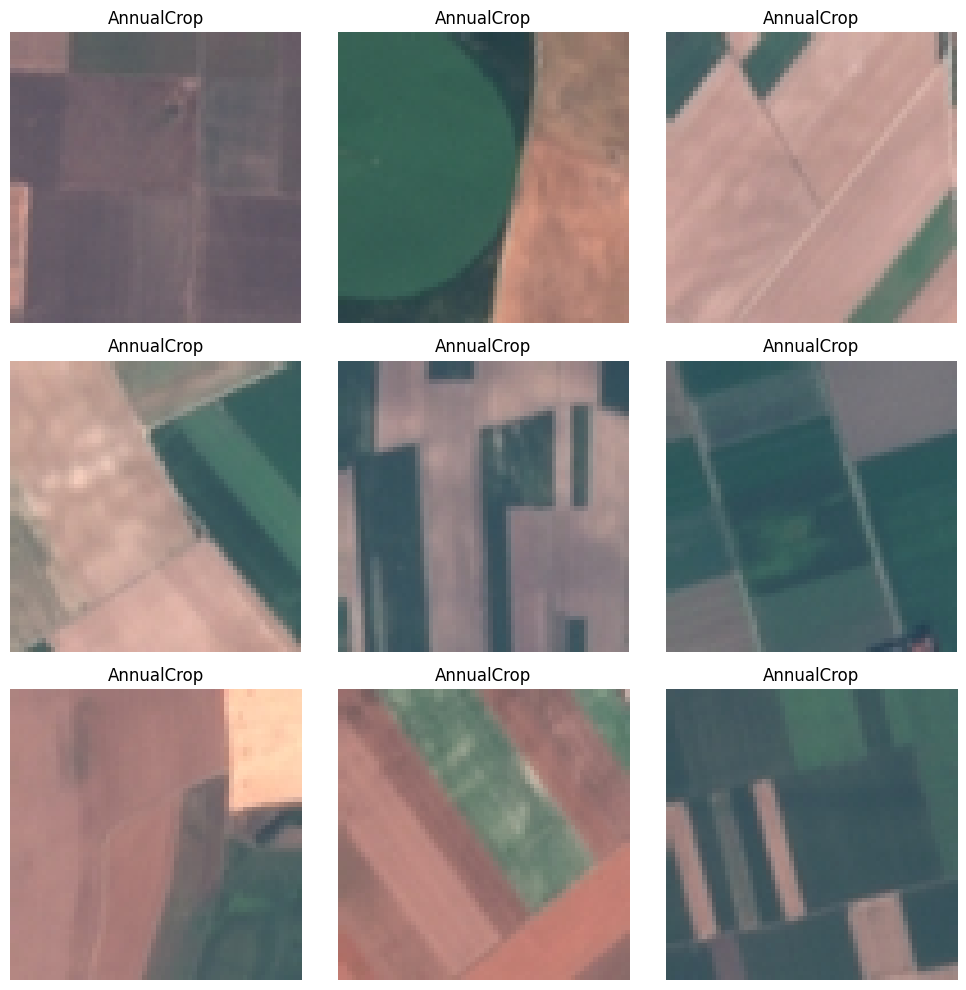

In [ ]:
#displaying satilite images
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    image, label = dataset[i]

    ax.imshow(image)
    ax.set_title(dataset.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#checking the image dimension
image, label = dataset[0]

print("Image dimensions:", image.size)
print("Image mode:", image.mode)
print("Label number:", label)
print("Label name:", dataset.classes[label])

Image dimensions: (64, 64)
Image mode: RGB
Label number: 0
Label name: AnnualCrop


In [ ]:
#creating the image transmation

from torchvision import transforms

# Transformations for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transformations for validation and test images
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created successfully!")

Image transformations created successfully!


In [ ]:
#spliting the datasets

from torchvision import datasets
from torch.utils.data import random_split

data_dir = "/content/eurosat_data"

# Create separate dataset objects with different transforms
train_full = datasets.EuroSAT(
    root=data_dir,
    download=False,
    transform=train_transform
)

eval_full = datasets.EuroSAT(
    root=data_dir,
    download=False,
    transform=test_transform
)

# Reproducible split
total_size = len(train_full)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = __import__("torch").Generator().manual_seed(42)

train_subset, val_subset, test_subset = random_split(
    train_full,
    [train_size, val_size, test_size],
    generator=generator
)

# Use evaluation transforms for validation and test data
from torch.utils.data import Subset

val_set = Subset(eval_full, val_subset.indices)
test_set = Subset(eval_full, test_subset.indices)
train_set = train_subset

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Testing images:", len(test_set))
print("Total images:", len(train_set) + len(val_set) + len(test_set))

Training images: 21600
Validation images: 2700
Testing images: 2700
Total images: 27000


In [ ]:
#craeting the data loader

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 675
Validation batches: 85
Testing batches: 85


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 5 labels:", labels[:5].tolist())


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 5 labels: [4, 1, 7, 1, 2]


In [ ]:
#loadinng an pretained model

import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained ResNet50 weights
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer for 10 land-cover classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(dataset.classes))

# Move model to GPU or CPU
model = model.to(device)

print("Device:", device)
print("Number of classes:", len(dataset.classes))
print("Final layer:", model.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


Device: cuda
Number of classes: 10
Final layer: Linear(in_features=2048, out_features=10, bias=True)


In [ ]:
#define the loss function and optimizer

import torch.nn as nn
import torch.optim as optim

# Measures how incorrect the model's predictions are
criterion = nn.CrossEntropyLoss()

# Updates only the newly added classification layer
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
#train and vaildate the model
import torch

NUM_EPOCHS = 5

for epoch in range(NUM_EPOCHS):
    # Training phase
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)

        correct_train += (predictions == labels).sum().item()
        total_train += labels.size(0)

    train_accuracy = correct_train / total_train

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct_val += (predictions == labels).sum().item()
            total_val += labels.size(0)

    val_accuracy = correct_val / total_val
    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Epoch [1/5] | Loss: 0.6034 | Train Accuracy: 83.13% | Validation Accuracy: 90.70%
Epoch [2/5] | Loss: 0.3260 | Train Accuracy: 89.70% | Validation Accuracy: 91.96%
Epoch [3/5] | Loss: 0.2784 | Train Accuracy: 91.20% | Validation Accuracy: 93.30%
Epoch [4/5] | Loss: 0.2502 | Train Accuracy: 91.87% | Validation Accuracy: 93.56%
Epoch [5/5] | Loss: 0.2324 | Train Accuracy: 92.39% | Validation Accuracy: 93.78%


In [ ]:
#saving the trained model

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": dataset.classes
    },
    "/content/satellite_classifier.pth"
)
print("Model saved successfully!")

Model saved successfully!


In [ ]:
#evaluvate the model on test set

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)

print(f"Test Accuracy: {test_accuracy:.2%}")
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(dataset.classes))),
    target_names=dataset.classes,
    zero_division=0
))

Test Accuracy: 93.19%

Classification Report:

                      precision    recall  f1-score   support

          AnnualCrop       0.90      0.94      0.92       300
              Forest       0.95      0.99      0.97       297
HerbaceousVegetation       0.94      0.92      0.93       302
             Highway       0.88      0.85      0.87       269
          Industrial       0.97      0.94      0.95       257
             Pasture       0.87      0.95      0.91       187
       PermanentCrop       0.92      0.92      0.92       254
         Residential       0.98      0.97      0.98       314
               River       0.90      0.86      0.88       245
             SeaLake       0.98      0.96      0.97       275

            accuracy                           0.93      2700
           macro avg       0.93      0.93      0.93      2700
        weighted avg       0.93      0.93      0.93      2700



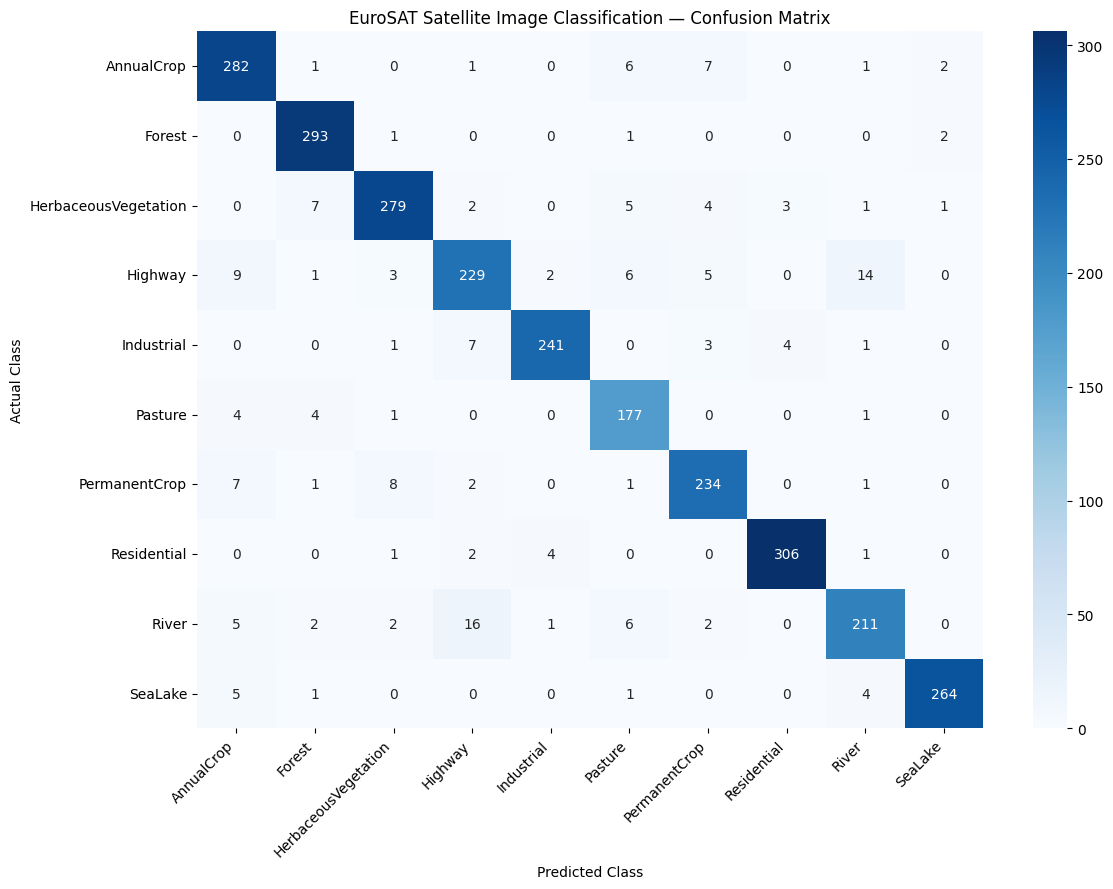

In [ ]:
#visualization of confusion matrix

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(dataset.classes)))
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EuroSAT Satellite Image Classification — Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#save the baseline model

import torch

baseline_path = "/content/satellite_classifier_baseline.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": dataset.classes,
        "test_accuracy": test_accuracy
    },
    baseline_path
)

print("Baseline model saved:", baseline_path)

Baseline model saved: /content/satellite_classifier_baseline.pth


In [ ]:
#unfreeze the model

# Allow all ResNet50 layers to learn
for param in model.parameters():
    param.requires_grad = True

# Use a smaller learning rate for fine-tuning
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("All model layers are now trainable.")
print("Fine-tuning learning rate: 0.0001")

All model layers are now trainable.
Fine-tuning learning rate: 0.0001


In [ ]:
#fine tune for the three epochs

NUM_FINE_TUNE_EPOCHS = 3

for epoch in range(NUM_FINE_TUNE_EPOCHS):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)

        correct_train += (predictions == labels).sum().item()
        total_train += labels.size(0)

    train_accuracy = correct_train / total_train

    model.eval()
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct_val += (predictions == labels).sum().item()
            total_val += labels.size(0)

    val_accuracy = correct_val / total_val
    avg_loss = running_loss / len(train_loader)

    print(
        f"Fine-tune Epoch [{epoch+1}/{NUM_FINE_TUNE_EPOCHS}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Accuracy: {val_accuracy:.2%}"
    )

Fine-tune Epoch [1/3] | Loss: 0.1349 | Train Accuracy: 95.47% | Validation Accuracy: 97.59%
Fine-tune Epoch [2/3] | Loss: 0.0726 | Train Accuracy: 97.56% | Validation Accuracy: 97.63%
Fine-tune Epoch [3/3] | Loss: 0.0483 | Train Accuracy: 98.30% | Validation Accuracy: 97.33%


In [ ]:
#saving the fine tune model

import torch

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": dataset.classes,
        "validation_accuracy": 0.9733,
        "epoch": 3
    },
    "/content/satellite_classifier_finetuned.pth"
)

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!


In [ ]:
#evaluate the fine tuning model

from sklearn.metrics import accuracy_score, classification_report

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

finetuned_test_accuracy = accuracy_score(
    all_labels, all_preds
)

print(f"Fine-tuned Test Accuracy: {finetuned_test_accuracy:.2%}")

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(dataset.classes))),
    target_names=dataset.classes,
    zero_division=0
))

Fine-tuned Test Accuracy: 97.44%
                      precision    recall  f1-score   support

          AnnualCrop       0.99      0.98      0.98       300
              Forest       1.00      0.99      0.99       297
HerbaceousVegetation       0.98      0.99      0.98       302
             Highway       0.98      0.94      0.96       269
          Industrial       1.00      0.93      0.96       257
             Pasture       0.99      0.97      0.98       187
       PermanentCrop       0.97      0.98      0.97       254
         Residential       0.94      1.00      0.97       314
               River       0.93      0.98      0.95       245
             SeaLake       0.99      0.99      0.99       275

            accuracy                           0.97      2700
           macro avg       0.98      0.97      0.97      2700
        weighted avg       0.98      0.97      0.97      2700



In [ ]:
#saving the trained model

import torch

checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": dataset.classes
}

torch.save(
    checkpoint,
    "/content/satellite_classifier_finetuned.pth"
)

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [ ]:
#download the dataset
from torchvision import datasets

data_dir = "/content/eurosat_data"

dataset = datasets.EuroSAT(
    root=data_dir,
    download=True
)

print("Dataset downloaded successfully!")
print("Total images:", len(dataset))
print("Classes:", dataset.classes)

Dataset downloaded successfully!
Total images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:

image, label = dataset[0]

image_path = "/content/test_satellite_image.jpg"
image.save(image_path)

print("Image saved successfully!")
print("Actual class:", dataset.classes[label])

Image saved successfully!
Actual class: AnnualCrop


Actual class: AnnualCrop
Predicted class: AnnualCrop
Confidence: 99.93%


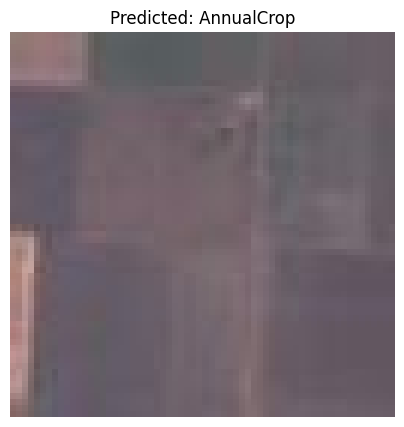

In [ ]:
#predition cell

from PIL import Image
import torch
import matplotlib.pyplot as plt

image = Image.open(
    "/content/test_satellite_image.jpg"
).convert("RGB")

input_tensor = test_transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

predicted_index = probabilities.argmax().item()

print("Actual class:", dataset.classes[label])
print("Predicted class:", dataset.classes[predicted_index])
print(f"Confidence: {probabilities[predicted_index].item() * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Predicted: {dataset.classes[predicted_index]}")
plt.axis("off")
plt.show()

Satellite Image Change Detection for Potential Deforestation.

In [ ]:
#creating two sample land cover maps

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Each cell represents a land patch
# 0 = Forest, 1 = AnnualCrop,
# 2 = Pasture, 3 = Residential

year1 = np.zeros((8, 8), dtype=int)

# Simulate land cover changes in the later year
year2 = year1.copy()

# Forest converted to annual crop
year2[1, 2] = 1
year2[1, 3] = 1
year2[2, 2] = 1

# Forest converted to pasture
year2[4, 5] = 2
year2[4, 6] = 2

# Forest converted to residential
year2[6, 1] = 3

class_names = [
    "Forest",
    "AnnualCrop",
    "Pasture",
    "Residential"
]

print("Year 1 map shape:", year1.shape)
print("Year 2 map shape:", year2.shape)

Year 1 map shape: (8, 8)
Year 2 map shape: (8, 8)


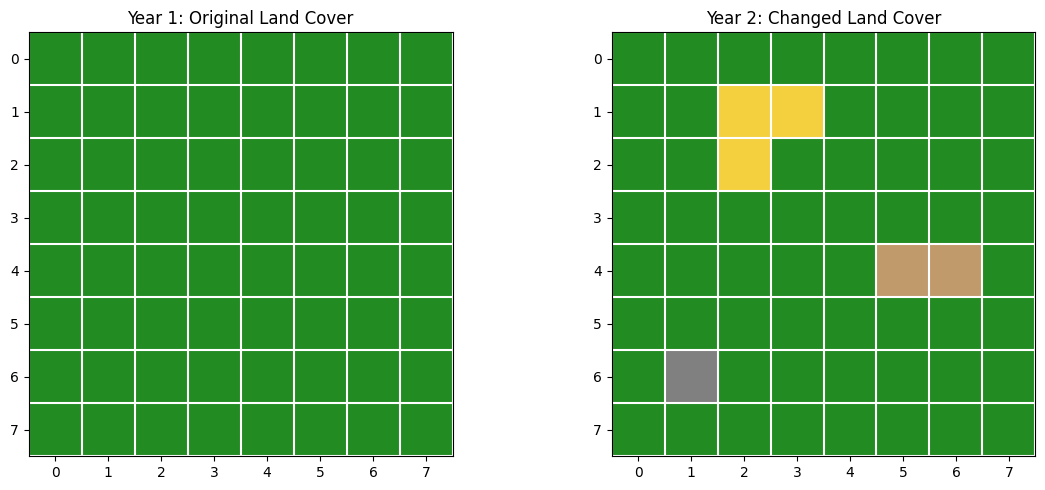

In [ ]:
#visualize both maps

colors = [
    "#228B22",  # Forest
    "#F4D03F",  # AnnualCrop
    "#C19A6B",  # Pasture
    "#808080"   # Residential
]

land_cover_cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(year1, cmap=land_cover_cmap, vmin=0, vmax=3)
axes[0].set_title("Year 1: Original Land Cover")

axes[1].imshow(year2, cmap=land_cover_cmap, vmin=0, vmax=3)
axes[1].set_title("Year 2: Changed Land Cover")

for ax in axes:
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

In [ ]:
#detect pootenial deforestation

# True wherever forest in Year 1 becomes non-forest in Year 2
deforestation_mask = (
    (year1 == 0) &
    (year2 != 0)
)

print("Potential change locations:")
print(deforestation_mask.astype(int))

print(
    "Potentially changed patches:",
    int(deforestation_mask.sum())
)

Potential change locations:
[[0 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0]
 [0 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
Potentially changed patches: 6


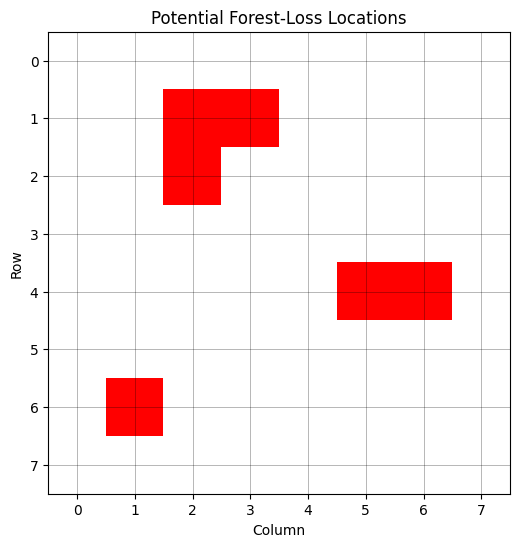

In [ ]:
#visualize the detected changes

plt.figure(figsize=(7, 6))

plt.imshow(
    deforestation_mask,
    cmap=ListedColormap(["white", "red"]),
    vmin=0,
    vmax=1
)

plt.title("Potential Forest-Loss Locations")
plt.xlabel("Column")
plt.ylabel("Row")

plt.xticks(range(8))
plt.yticks(range(8))
plt.grid(color="black", linewidth=0.5, alpha=0.4)

plt.show()

In [ ]:
#genrate the change report

changed_rows, changed_cols = np.where(deforestation_mask)

change_report = []

for row, col in zip(changed_rows, changed_cols):
    old_class = class_names[year1[row, col]]
    new_class = class_names[year2[row, col]]

    change_report.append({
        "row": int(row),
        "column": int(col),
        "previous_class": old_class,
        "current_class": new_class,
        "change": f"{old_class} -> {new_class}"
    })

for event in change_report:
    print(event)

print("\nTotal potential change events:", len(change_report))

{'row': 1, 'column': 2, 'previous_class': 'Forest', 'current_class': 'AnnualCrop', 'change': 'Forest -> AnnualCrop'}
{'row': 1, 'column': 3, 'previous_class': 'Forest', 'current_class': 'AnnualCrop', 'change': 'Forest -> AnnualCrop'}
{'row': 2, 'column': 2, 'previous_class': 'Forest', 'current_class': 'AnnualCrop', 'change': 'Forest -> AnnualCrop'}
{'row': 4, 'column': 5, 'previous_class': 'Forest', 'current_class': 'Pasture', 'change': 'Forest -> Pasture'}
{'row': 4, 'column': 6, 'previous_class': 'Forest', 'current_class': 'Pasture', 'change': 'Forest -> Pasture'}
{'row': 6, 'column': 1, 'previous_class': 'Forest', 'current_class': 'Residential', 'change': 'Forest -> Residential'}

Total potential change events: 6


In [ ]:
#build a reusable image-patch classifier

from PIL import Image
import numpy as np
import torch

def classify_satellite_image(
    satellite_image,
    patch_size=64,
    batch_size=32
):
    """
    Classify a satellite image patch by patch.

    Returns:
        A 2D array of predicted class indices.
    """

    satellite_image = satellite_image.convert("RGB")

    width, height = satellite_image.size

    grid_width = width // patch_size
    grid_height = height // patch_size

    patches = []

    for row in range(grid_height):
        for col in range(grid_width):
            left = col * patch_size
            top = row * patch_size

            patch = satellite_image.crop((
                left,
                top,
                left + patch_size,
                top + patch_size
            ))

            patches.append((row, col, patch))

    class_map = np.full(
        (grid_height, grid_width),
        -1,
        dtype=int
    )

    model.eval()

    with torch.no_grad():
        for start in range(0, len(patches), batch_size):
            batch = patches[start:start + batch_size]

            tensors = torch.stack([
                test_transform(patch)
                for _, _, patch in batch
            ]).to(device)

            outputs = model(tensors)
            predictions = outputs.argmax(dim=1).cpu().numpy()

            for (row, col, _), prediction in zip(
                batch, predictions
            ):
                class_map[row, col] = prediction

    return class_map


print("Patch classification function created!")

Patch classification function created!


In [ ]:
#test the funcation

sample_image, sample_label = dataset[0]

predicted_map = classify_satellite_image(sample_image)

print("Actual image class:", dataset.classes[sample_label])
print("Predicted patch map:")
print(predicted_map)

Actual image class: AnnualCrop
Predicted patch map:
[[0]]


In [ ]:
#confirm the class mapping

for index, class_name in enumerate(dataset.classes):
    print(index, ":", class_name)

0 : AnnualCrop
1 : Forest
2 : HerbaceousVegetation
3 : Highway
4 : Industrial
5 : Pasture
6 : PermanentCrop
7 : Residential
8 : River
9 : SeaLake


In [ ]:
#Test the patch classifier on a larger image

from PIL import Image

sample_image, sample_label = dataset[0]

# Create a 256 × 256 test image
large_image = Image.new("RGB", (256, 256))

for row in range(4):
    for col in range(4):
        large_image.paste(sample_image, (col * 64, row * 64))

large_class_map = classify_satellite_image(large_image)

print("Actual source class:", dataset.classes[sample_label])
print("Predicted map:\n", large_class_map)
print("Map shape:", large_class_map.shape)

Actual source class: AnnualCrop
Predicted map:
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
Map shape: (4, 4)


In [ ]:
#Prepare the real change-detection rule

import numpy as np

def detect_forest_loss(class_map_year1, class_map_year2):
    if class_map_year1.shape != class_map_year2.shape:
        raise ValueError(
            "Both maps must have the same dimensions."
        )

    # Class index 1 represents Forest
    forest_mask = class_map_year1 == 1

    # Selected non-forest classes that may indicate forest conversion
    conversion_classes = [0, 4, 5, 7]

    converted_mask = np.isin(
        class_map_year2,
        conversion_classes
    )

    # Potential forest loss
    loss_mask = forest_mask & converted_mask

    return loss_mask


print("Deforestation comparison function created!")

Deforestation comparison function created!


In [ ]:
#test the deforestation comparison function
import numpy as np

# Simulated land-cover map for Year 1
year1 = np.array([
    [1, 1, 1, 0],
    [1, 1, 1, 0],
    [1, 1, 1, 0],
    [0, 0, 0, 0]
])

# Simulated land-cover map for Year 2
year2 = np.array([
    [1, 0, 1, 0],
    [1, 4, 1, 0],
    [1, 5, 7, 0],
    [0, 0, 0, 0]
])

loss_mask = detect_forest_loss(year1, year2)

print("Forest-loss mask:")
print(loss_mask.astype(int))

print("Potential forest-loss patches:", np.sum(loss_mask))

Forest-loss mask:
[[0 1 0 0]
 [0 1 0 0]
 [0 1 1 0]
 [0 0 0 0]]
Potential forest-loss patches: 4


In [ ]:
#uploading the satellite images
from google.colab import files

uploaded = files.upload()

Saving HLS.S30.T43PGM.2025087T050659.v2.0.B02.tif to HLS.S30.T43PGM.2025087T050659.v2.0.B02.tif
Saving HLS.S30.T43PGM.2025087T050659.v2.0.B03.tif to HLS.S30.T43PGM.2025087T050659.v2.0.B03.tif
Saving HLS.S30.T43PGM.2025087T050659.v2.0.B04.tif to HLS.S30.T43PGM.2025087T050659.v2.0.B04.tif
Saving HLS.S30.T43PGM.2021088T050649.v2.0.B03.tif to HLS.S30.T43PGM.2021088T050649.v2.0.B03.tif
Saving HLS.S30.T43PGM.2021088T050649.v2.0.B02.tif to HLS.S30.T43PGM.2021088T050649.v2.0.B02.tif
Saving HLS.S30.T43PGM.2021088T050649.v2.0.B04.tif to HLS.S30.T43PGM.2021088T050649.v2.0.B04.tif


In [ ]:
#verifying the file name
for filename in uploaded.keys():
    print(filename)

HLS.S30.T43PGM.2025087T050659.v2.0.B02.tif
HLS.S30.T43PGM.2025087T050659.v2.0.B03.tif
HLS.S30.T43PGM.2025087T050659.v2.0.B04.tif
HLS.S30.T43PGM.2021088T050649.v2.0.B03.tif
HLS.S30.T43PGM.2021088T050649.v2.0.B02.tif
HLS.S30.T43PGM.2021088T050649.v2.0.B04.tif


In [ ]:
!pip install -q rasterio matplotlib

In [ ]:
import rasterio

for filename in uploaded.keys():
    with rasterio.open(filename) as src:
        print("\nFile:", filename)
        print("Size:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)


File: HLS.S30.T43PGM.2025087T050659.v2.0.B02.tif
Size: 3660 x 3660
CRS: EPSG:32643
Resolution: (30.0, 30.0)
Bounds: BoundingBox(left=699960.0, bottom=1090200.0, right=809760.0, top=1200000.0)

File: HLS.S30.T43PGM.2025087T050659.v2.0.B03.tif
Size: 3660 x 3660
CRS: EPSG:32643
Resolution: (30.0, 30.0)
Bounds: BoundingBox(left=699960.0, bottom=1090200.0, right=809760.0, top=1200000.0)

File: HLS.S30.T43PGM.2025087T050659.v2.0.B04.tif
Size: 3660 x 3660
CRS: EPSG:32643
Resolution: (30.0, 30.0)
Bounds: BoundingBox(left=699960.0, bottom=1090200.0, right=809760.0, top=1200000.0)

File: HLS.S30.T43PGM.2021088T050649.v2.0.B03.tif
Size: 3660 x 3660
CRS: PROJCS["UTM Zone 43, Northern Hemisphere",GEOGCS["Unknown datum based upon the WGS 84 ellipsoid",DATUM["Not specified (based on WGS 84 spheroid)",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude

In [ ]:
#Combine the three bands for each year
import numpy as np
import rasterio
import matplotlib.pyplot as plt

files_by_year = {
    2021: {
        "B02": "HLS.S30.T43PGM.2021088T050649.v2.0.B02.tif",
        "B03": "HLS.S30.T43PGM.2021088T050649.v2.0.B03.tif",
        "B04": "HLS.S30.T43PGM.2021088T050649.v2.0.B04.tif",
    },
    2025: {
        "B02": "HLS.S30.T43PGM.2025087T050659.v2.0.B02.tif",
        "B03": "HLS.S30.T43PGM.2025087T050659.v2.0.B03.tif",
        "B04": "HLS.S30.T43PGM.2025087T050659.v2.0.B04.tif",
    }
}

rgb_images = {}

for year, bands in files_by_year.items():
    arrays = {}

    for band, filename in bands.items():
        with rasterio.open(filename) as src:
            arrays[band] = src.read(1).astype(np.float32)

    # RGB order: Red, Green, Blue
    rgb = np.stack([
        arrays["B04"],
        arrays["B03"],
        arrays["B02"]
    ], axis=-1)

    rgb_images[year] = rgb

print("RGB image shapes:")
for year, rgb in rgb_images.items():
    print(year, rgb.shape)

RGB image shapes:
2021 (3660, 3660, 3)
2025 (3660, 3660, 3)


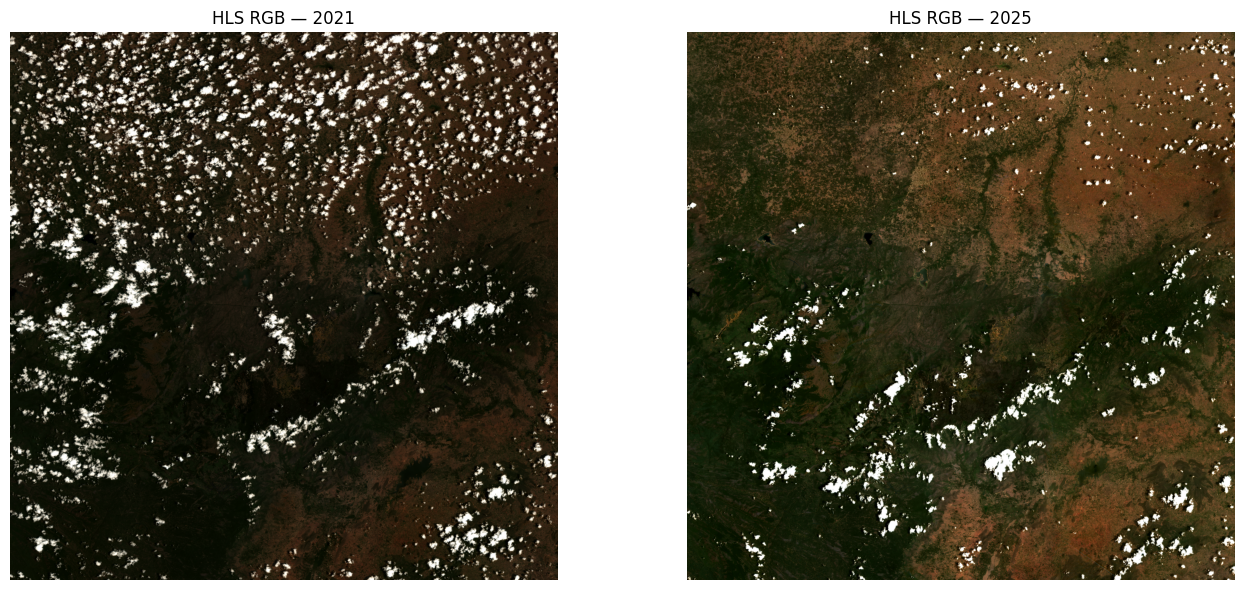

In [ ]:
#display both the satellite images
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, year in zip(axes, [2021, 2025]):
    rgb = rgb_images[year]

    # Exclude zero-valued pixels when estimating display limits
    valid = np.all(np.isfinite(rgb), axis=-1) & np.all(rgb > 0, axis=-1)

    low, high = np.percentile(rgb[valid], [2, 98])
    display = np.clip((rgb - low) / (high - low + 1e-6), 0, 1)

    ax.imshow(display)
    ax.set_title(f"HLS RGB — {year}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#loading the fine tuned model
import torch
import torch.nn as nn
from torchvision import models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    "/content/satellite_classifier_finetuned.pth",
    map_location=device,
    weights_only=False
)

class_names = checkpoint["class_names"]

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Model loaded successfully.")
print("Classes:", class_names)

Model loaded successfully.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
#prepare the RGB images for classification
from torchvision import transforms

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
#Classify the satellite images by patches
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch

PATCH_SIZE = 64
BATCH_SIZE = 64

def classify_rgb_image(rgb, patch_size=PATCH_SIZE, batch_size=BATCH_SIZE):
    height, width, _ = rgb.shape

    grid_h = height // patch_size
    grid_w = width // patch_size

    class_map = np.full((grid_h, grid_w), -1, dtype=np.int16)
    confidence_map = np.zeros((grid_h, grid_w), dtype=np.float32)

    patches = []
    positions = []

    # Convert reflectance to an 8-bit display-like RGB image.
    # This is exploratory preprocessing, not calibrated reflectance.
    valid_pixels = np.all(np.isfinite(rgb), axis=-1) & np.all(rgb > 0, axis=-1)
    low, high = np.percentile(rgb[valid_pixels], [2, 98])
    rgb8 = np.clip((rgb - low) / (high - low + 1e-6), 0, 1)
    rgb8 = (rgb8 * 255).astype(np.uint8)

    for row in range(grid_h):
        for col in range(grid_w):
            y1, x1 = row * patch_size, col * patch_size
            patch = rgb8[y1:y1 + patch_size, x1:x1 + patch_size]

            patches.append(test_transform(Image.fromarray(patch)))
            positions.append((row, col))

    model.eval()

    with torch.no_grad():
        for start in range(0, len(patches), batch_size):
            batch = torch.stack(
                patches[start:start + batch_size]
            ).to(device)

            probabilities = torch.softmax(model(batch), dim=1)
            confidence, predictions = probabilities.max(dim=1)

            for pos, pred, conf in zip(
                positions[start:start + batch_size],
                predictions.cpu().numpy(),
                confidence.cpu().numpy()
            ):
                row, col = pos
                class_map[row, col] = pred
                confidence_map[row, col] = conf

    return class_map, confidence_map

In [ ]:
#Generate the 2021 and 2025 land-cover maps
class_maps = {}
confidence_maps = {}

for year in [2021, 2025]:
    class_maps[year], confidence_maps[year] = classify_rgb_image(
        rgb_images[year]
    )

    print(
        year,
        "map shape:", class_maps[year].shape,
        "| patches:", class_maps[year].size
    )

2021 map shape: (57, 57) | patches: 3249
2025 map shape: (57, 57) | patches: 3249


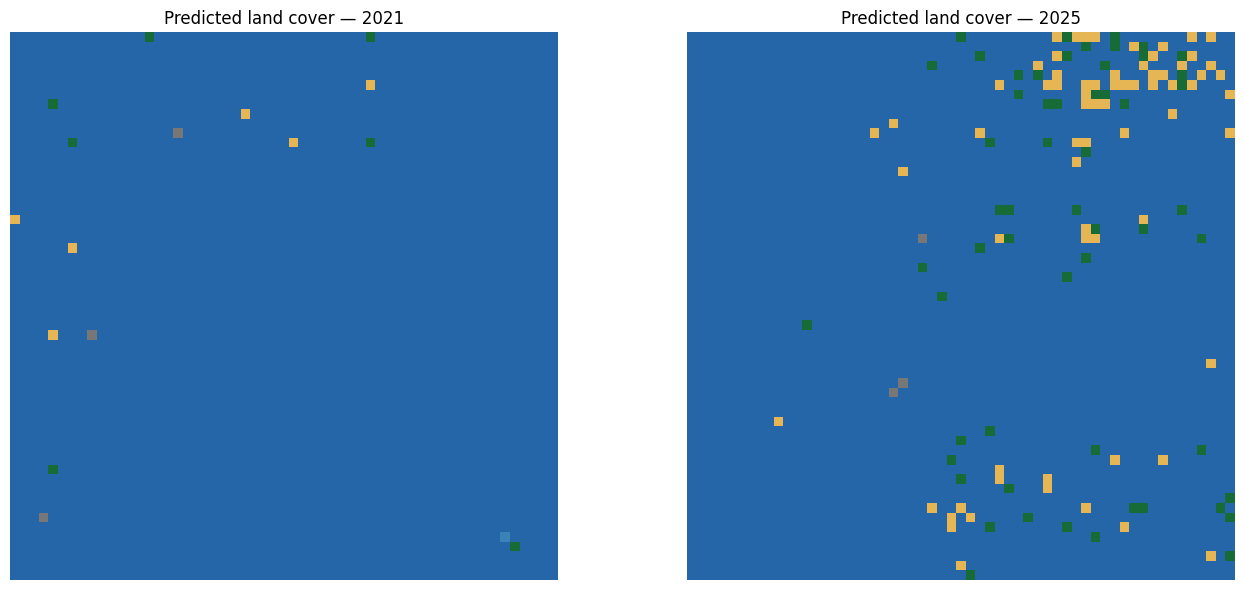

Class mapping:
0 : AnnualCrop
1 : Forest
2 : HerbaceousVegetation
3 : Highway
4 : Industrial
5 : Pasture
6 : PermanentCrop
7 : Residential
8 : River
9 : SeaLake


In [ ]:
#Visualize the predicted classes
from matplotlib.colors import ListedColormap

colors = [
    "#e6b655", "#176b36", "#8dbb65", "#777777", "#8b5a2b",
    "#b8a46a", "#b3cf72", "#b85b4b", "#3b82b7", "#2466a8"
]

cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, year in zip(axes, [2021, 2025]):
    ax.imshow(class_maps[year], cmap=cmap, vmin=0, vmax=9)
    ax.set_title(f"Predicted land cover — {year}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Class mapping:")
for i, name in enumerate(class_names):
    print(i, ":", name)

In [ ]:
#Check which classes the model is predicting
import numpy as np

for year in [2021, 2025]:
    class_map = class_maps[year]
    confidence = confidence_maps[year]

    print(f"\n--- {year} ---")

    for i, name in enumerate(class_names):
        count = np.sum(class_map == i)
        percentage = count / class_map.size * 100
        print(f"{name:25s}: {percentage:6.2f}%")

    print("Mean prediction confidence:", round(float(confidence.mean()), 3))


--- 2021 ---
AnnualCrop               :   0.18%
Forest                   :   0.22%
HerbaceousVegetation     :   0.00%
Highway                  :   0.09%
Industrial               :   0.00%
Pasture                  :   0.00%
PermanentCrop            :   0.00%
Residential              :   0.00%
River                    :   0.03%
SeaLake                  :  99.48%
Mean prediction confidence: 0.999

--- 2025 ---
AnnualCrop               :   2.12%
Forest                   :   1.75%
HerbaceousVegetation     :   0.00%
Highway                  :   0.09%
Industrial               :   0.00%
Pasture                  :   0.00%
PermanentCrop            :   0.00%
Residential              :   0.00%
River                    :   0.00%
SeaLake                  :  96.03%
Mean prediction confidence: 0.985



2021
Valid pixel percentage: 98.91
Red (B04) | min: 1.0 | median: 730.0 | max: 10263.0
Green (B03) | min: 9.0 | median: 649.0 | max: 9942.0
Blue (B02) | min: 1.0 | median: 364.0 | max: 9251.0

2025
Valid pixel percentage: 99.56
Red (B04) | min: 1.0 | median: 635.0 | max: 9884.0
Green (B03) | min: 36.0 | median: 603.0 | max: 9790.0
Blue (B02) | min: 1.0 | median: 332.0 | max: 9286.0


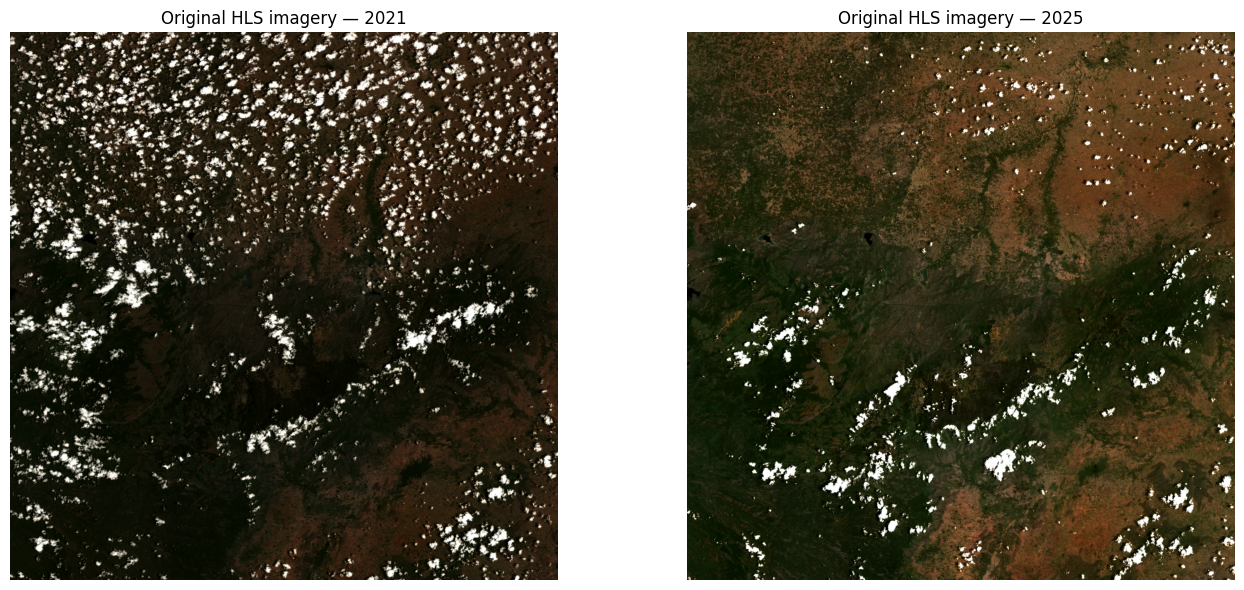

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, year in zip(axes, [2021, 2025]):
    rgb = rgb_images[year]

    valid = np.all(np.isfinite(rgb), axis=-1) & np.all(rgb > 0, axis=-1)

    print(f"\n{year}")
    print("Valid pixel percentage:", round(valid.mean() * 100, 2))

    for i, band in enumerate(["Red (B04)", "Green (B03)", "Blue (B02)"]):
        values = rgb[..., i][valid]
        print(
            band,
            "| min:", round(float(np.min(values)), 2),
            "| median:", round(float(np.median(values)), 2),
            "| max:", round(float(np.max(values)), 2)
        )

    # Display stretch for visual inspection only
    low, high = np.percentile(rgb[valid], [2, 98])
    display = np.clip((rgb - low) / (high - low + 1e-6), 0, 1)

    ax.imshow(display)
    ax.set_title(f"Original HLS imagery — {year}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

uploaded_extra = files.upload()

Saving HLS.S30.T43PGM.2021088T050649.v2.0.B05.tif to HLS.S30.T43PGM.2021088T050649.v2.0.B05.tif
Saving HLS.S30.T43PGM.2021088T050649.v2.0.Fmask.tif to HLS.S30.T43PGM.2021088T050649.v2.0.Fmask.tif
Saving HLS.S30.T43PGM.2025087T050659.v2.0.Fmask.tif to HLS.S30.T43PGM.2025087T050659.v2.0.Fmask.tif
Saving HLS.S30.T43PGM.2025087T050659.v2.0.B05.tif to HLS.S30.T43PGM.2025087T050659.v2.0.B05.tif


In [ ]:
for filename in uploaded_extra.keys():
    print(filename)

HLS.S30.T43PGM.2021088T050649.v2.0.B05.tif
HLS.S30.T43PGM.2021088T050649.v2.0.Fmask.tif
HLS.S30.T43PGM.2025087T050659.v2.0.Fmask.tif
HLS.S30.T43PGM.2025087T050659.v2.0.B05.tif


In [ ]:
import rasterio

for filename in uploaded_extra.keys():
    with rasterio.open(filename) as src:
        print("\nFile:", filename)
        print("Shape:", src.height, "x", src.width)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)
        print("Data type:", src.dtypes)


File: HLS.S30.T43PGM.2021088T050649.v2.0.B05.tif
Shape: 3660 x 3660
CRS: PROJCS["UTM Zone 43, Northern Hemisphere",GEOGCS["Unknown datum based upon the WGS 84 ellipsoid",DATUM["Not specified (based on WGS 84 spheroid)",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Resolution: (30.0, 30.0)
Bounds: BoundingBox(left=699960.0, bottom=1090200.0, right=809760.0, top=1200000.0)
Data type: ('int16',)

File: HLS.S30.T43PGM.2021088T050649.v2.0.Fmask.tif
Shape: 3660 x 3660
CRS: PROJCS["UTM Zone 43, Northern Hemisphere",GEOGCS["Unknown datum based upon the WGS 84 ellipsoid",DATUM["Not specified (based on WGS 84 spher

In [ ]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

files = {}

for name in list(uploaded.keys()) + list(uploaded_extra.keys()):
    upper = name.upper()

    if "2021088T050649" in upper:
        year = 2021
    elif "2025087T050659" in upper:
        year = 2025
    else:
        continue

    if "FMASK" in upper:
        band = "Fmask"
    elif "B04" in upper:
        band = "B04"
    elif "B05" in upper:
        band = "B05"
    else:
        continue

    files.setdefault(year, {})[band] = name

for year in [2021, 2025]:
    print(year, files.get(year, {}).keys())

2021 dict_keys(['B04', 'B05', 'Fmask'])
2025 dict_keys(['B04', 'Fmask', 'B05'])


In [ ]:
ndvi_maps = {}
valid_masks = {}

for year in [2021, 2025]:
    with rasterio.open(files[year]["B04"]) as src:
        red = src.read(1).astype(np.float32)
        red_nodata = src.nodata

    with rasterio.open(files[year]["B05"]) as src:
        nir = src.read(1).astype(np.float32)
        nir_nodata = src.nodata

    with rasterio.open(files[year]["Fmask"]) as src:
        qa = src.read(1).astype(np.uint8)

    # HLS Fmask bits: cloud, adjacent, shadow, snow/ice
    cloud = (qa & (1 << 1)) != 0
    adjacent = (qa & (1 << 2)) != 0
    shadow = (qa & (1 << 3)) != 0
    snow = (qa & (1 << 4)) != 0

    # Exclude fill values and non-finite reflectance
    valid = (
        np.isfinite(red) & np.isfinite(nir) &
        (red > -9990) & (nir > -9990) &
        ~cloud & ~adjacent & ~shadow & ~snow
    )

    if red_nodata is not None:
        valid &= red != red_nodata
    if nir_nodata is not None:
        valid &= nir != nir_nodata

    denominator = nir + red
    valid &= np.abs(denominator) > 1e-6

    ndvi = np.full(red.shape, np.nan, dtype=np.float32)
    ndvi[valid] = (
        (nir[valid] - red[valid]) /
        (nir[valid] + red[valid])
    )

    ndvi_maps[year] = ndvi
    valid_masks[year] = valid

    print(f"\n{year}")
    print("Cloud pixels (%):", round(cloud.mean() * 100, 2))
    print("Cloud-shadow pixels (%):", round(shadow.mean() * 100, 2))
    print("Valid pixels (%):", round(valid.mean() * 100, 2))
    print("Mean valid NDVI:", round(float(np.nanmean(ndvi)), 3))


2021
Cloud pixels (%): 39.08
Cloud-shadow pixels (%): 6.98
Valid pixels (%): 45.44
Mean valid NDVI: 0.234

2025
Cloud pixels (%): 17.0
Cloud-shadow pixels (%): 3.3
Valid pixels (%): 71.96
Mean valid NDVI: 0.22


/tmp/ipykernel_1724/842657998.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


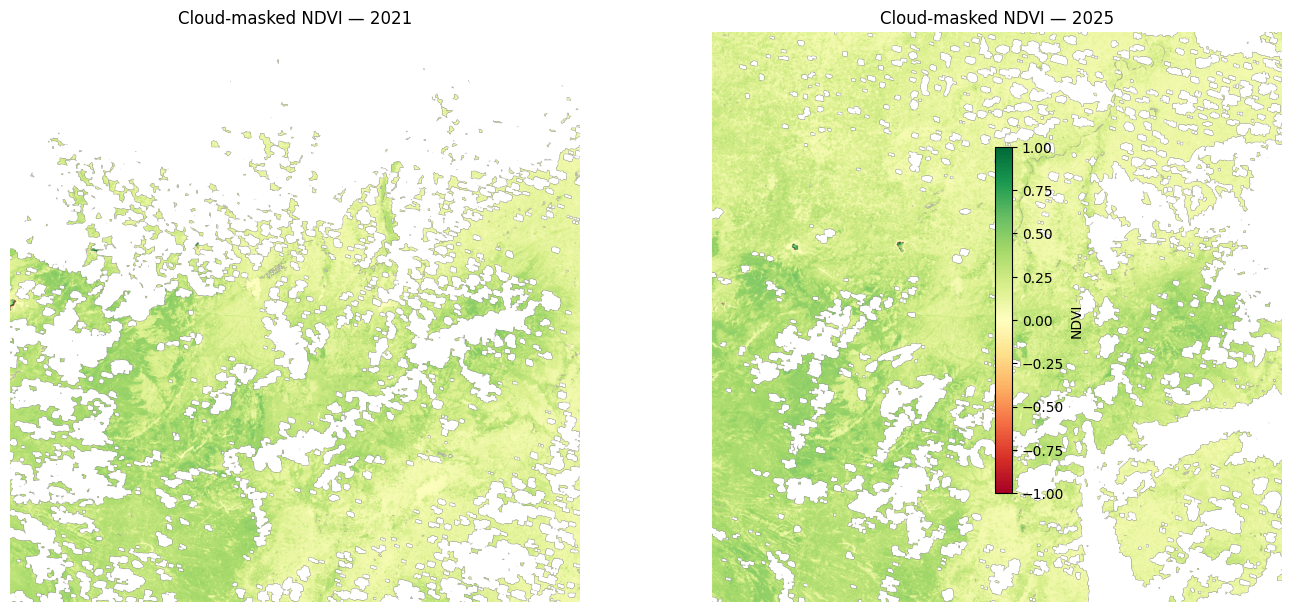

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, year in zip(axes, [2021, 2025]):
    image = ax.imshow(
        ndvi_maps[year],
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"Cloud-masked NDVI — {year}")
    ax.axis("off")

fig.colorbar(image, ax=axes, label="NDVI", shrink=0.75)
plt.tight_layout()
plt.show()

2021 crop shape: (333, 333) valid pixels (%): 18.44 mean NDVI: 0.366
2025 crop shape: (333, 333) valid pixels (%): 51.55 mean NDVI: 0.347


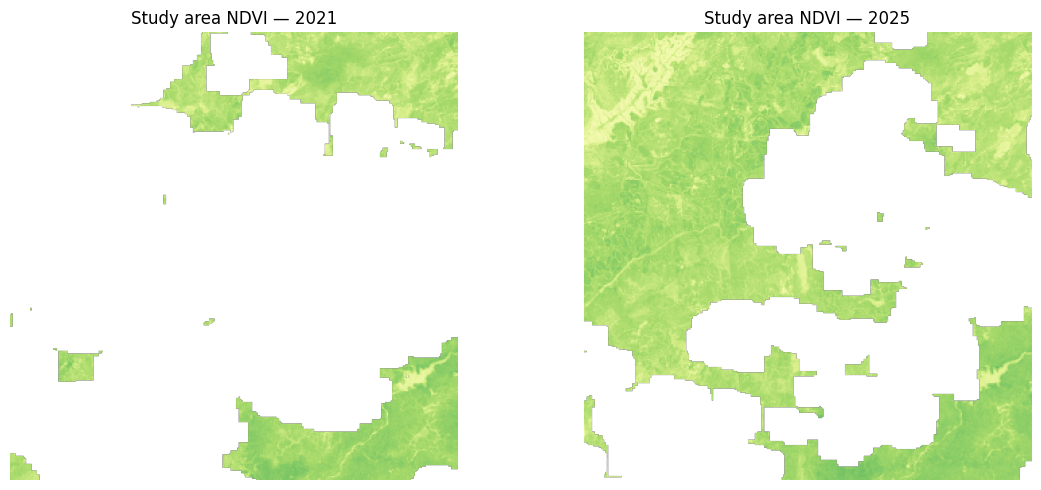

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from pyproj import Transformer
from rasterio.windows import from_bounds
from rasterio.transform import array_bounds

# Selected study location
latitude = 10.30
longitude = 76.95

# Convert geographic coordinates to the raster's UTM CRS
with rasterio.open(files[2021]["B04"]) as src:
    raster_crs = src.crs
    transformer = Transformer.from_crs(
        "EPSG:4326", raster_crs, always_xy=True
    )
    center_x, center_y = transformer.transform(
        longitude, latitude
    )

# Crop a 10 km x 10 km area around the point
buffer_m = 5000

left = center_x - buffer_m
right = center_x + buffer_m
bottom = center_y - buffer_m
top = center_y + buffer_m

window = from_bounds(
    left, bottom, right, top,
    transform=rasterio.open(files[2021]["B04"]).transform
).round_offsets().round_lengths()

# Keep the crop inside the raster boundaries
with rasterio.open(files[2021]["B04"]) as src:
    window = window.intersection(
        rasterio.windows.Window(0, 0, src.width, src.height)
    )

row_start = int(window.row_off)
row_end = row_start + int(window.height)
col_start = int(window.col_off)
col_end = col_start + int(window.width)

ndvi_crop = {}
valid_crop = {}

for year in [2021, 2025]:
    ndvi_crop[year] = ndvi_maps[year][
        row_start:row_end, col_start:col_end
    ]
    valid_crop[year] = valid_masks[year][
        row_start:row_end, col_start:col_end
    ]

    print(
        year,
        "crop shape:", ndvi_crop[year].shape,
        "valid pixels (%):",
        round(valid_crop[year].mean() * 100, 2),
        "mean NDVI:",
        round(float(np.nanmean(ndvi_crop[year])), 3)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, year in zip(axes, [2021, 2025]):
    ax.imshow(ndvi_crop[year], cmap="RdYlGn", vmin=-1, vmax=1)
    ax.set_title(f"Study area NDVI — {year}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Total pixels: 110889
Common valid pixels: 15648
Common valid coverage (%): 14.11
Mean NDVI 2021 (common pixels): 0.364
Mean NDVI 2025 (common pixels): 0.377
Mean NDVI change: 0.013


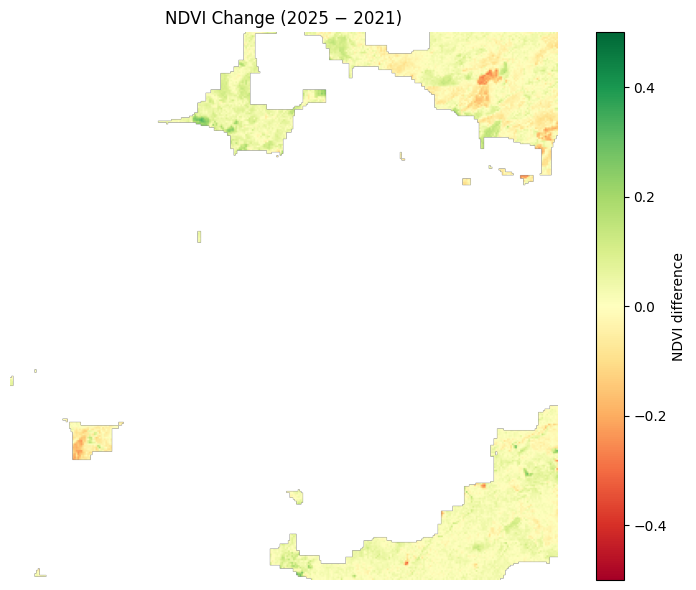

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Pixels that are valid in BOTH years
common_valid = (
    valid_crop[2021]
    & valid_crop[2025]
    & np.isfinite(ndvi_crop[2021])
    & np.isfinite(ndvi_crop[2025])
)

ndvi_2021 = ndvi_crop[2021]
ndvi_2025 = ndvi_crop[2025]

# Calculate changes only on common valid pixels
ndvi_change = np.full(ndvi_2021.shape, np.nan, dtype=np.float32)

ndvi_change[common_valid] = (
    ndvi_2025[common_valid] - ndvi_2021[common_valid]
)

print("Total pixels:", common_valid.size)
print("Common valid pixels:", int(common_valid.sum()))
print(
    "Common valid coverage (%):",
    round(common_valid.mean() * 100, 2)
)

if common_valid.any():
    print(
        "Mean NDVI 2021 (common pixels):",
        round(float(ndvi_2021[common_valid].mean()), 3)
    )
    print(
        "Mean NDVI 2025 (common pixels):",
        round(float(ndvi_2025[common_valid].mean()), 3)
    )
    print(
        "Mean NDVI change:",
        round(float(ndvi_change[common_valid].mean()), 3)
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(
        ndvi_change,
        cmap="RdYlGn",
        vmin=-0.5,
        vmax=0.5
    )
    ax.set_title("NDVI Change (2025 − 2021)")
    ax.axis("off")
    fig.colorbar(im, ax=ax, label="NDVI difference")
    plt.tight_layout()
    plt.show()
else:
    print("No common valid pixels. Check the crop alignment and masks.")

Common valid pixels: 15648
Pixels with NDVI decline below -0.15: 212
Potential vegetation-decline area (ha): 19.08
Share of common valid pixels with decline (%): 1.35


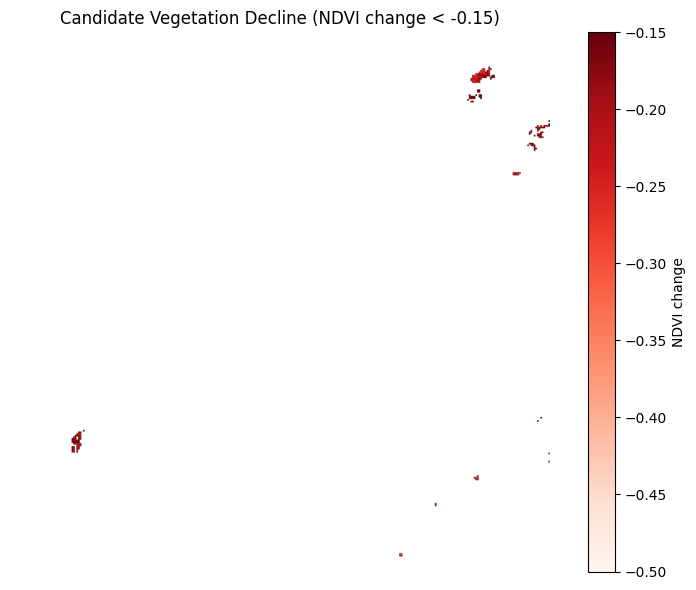

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Preliminary threshold, for screening only
decline_threshold = -0.15

decline_mask = (
    common_valid
    & (ndvi_change < decline_threshold)
)

stable_or_increased_mask = (
    common_valid
    & (ndvi_change >= decline_threshold)
)

pixel_area_ha = 0.09

decline_pixels = int(decline_mask.sum())
common_pixels = int(common_valid.sum())

print("Common valid pixels:", common_pixels)
print("Pixels with NDVI decline below -0.15:", decline_pixels)
print(
    "Potential vegetation-decline area (ha):",
    round(decline_pixels * pixel_area_ha, 2)
)

if common_pixels > 0:
    print(
        "Share of common valid pixels with decline (%):",
        round(decline_pixels / common_pixels * 100, 2)
    )

# Display only the candidate decline areas
decline_display = np.where(decline_mask, ndvi_change, np.nan)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(
    decline_display,
    cmap="Reds",
    vmin=-0.5,
    vmax=decline_threshold
)
ax.set_title("Candidate Vegetation Decline (NDVI change < -0.15)")
ax.axis("off")
fig.colorbar(im, ax=ax, label="NDVI change")
plt.tight_layout()
plt.show()

Number of connected clusters: 22
Largest cluster sizes (pixels): [70, 42, 16, 11, 11, 11, 9, 8, 6, 5]
Largest cluster areas (ha): [6.3, 3.78, 1.44, 0.99, 0.99, 0.99, 0.81, 0.72, 0.54, 0.45]


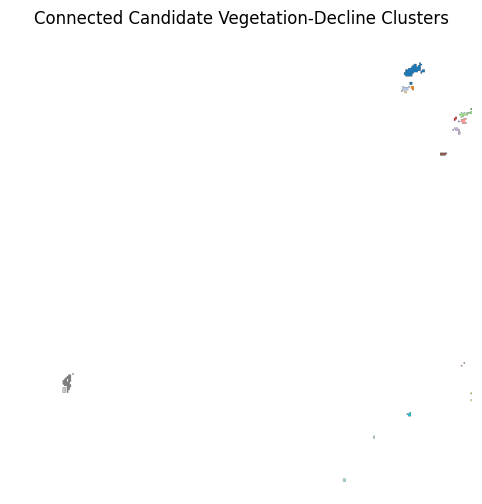

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Connected components among candidate decline pixels
structure = np.ones((3, 3), dtype=int)
labels, number_of_clusters = ndimage.label(
    decline_mask,
    structure=structure
)

cluster_sizes = np.bincount(labels.ravel())[1:]
cluster_sizes = np.sort(cluster_sizes)[::-1]

print("Number of connected clusters:", number_of_clusters)
print("Largest cluster sizes (pixels):", cluster_sizes[:10].tolist())
print(
    "Largest cluster areas (ha):",
    np.round(cluster_sizes[:10] * 0.09, 2).tolist()
)

# Display the connected clusters
cluster_map = np.where(decline_mask, labels, np.nan)

plt.figure(figsize=(8, 6))
plt.imshow(cluster_map, cmap="tab20")
plt.title("Connected Candidate Vegetation-Decline Clusters")
plt.axis("off")
plt.show()

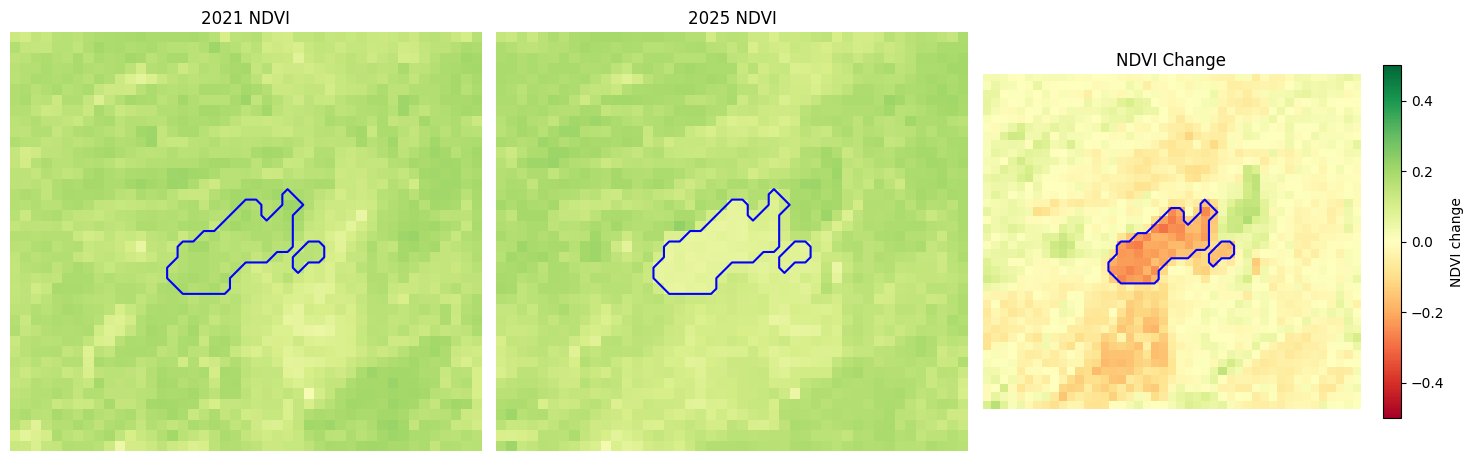

Largest cluster pixels: 70
Largest cluster area (ha): 6.3
Mean NDVI change inside cluster: -0.21


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# Recreate connected components
structure = np.ones((3, 3), dtype=int)
labels, number_of_clusters = ndimage.label(
    decline_mask,
    structure=structure
)

cluster_sizes = np.bincount(labels.ravel())
cluster_sizes[0] = 0  # Exclude background

# Largest connected cluster
largest_label = int(np.argmax(cluster_sizes))
largest_cluster = labels == largest_label

# Crop a small window around that cluster
rows, cols = np.where(largest_cluster)

r0, r1 = max(rows.min() - 15, 0), min(rows.max() + 16, labels.shape[0])
c0, c1 = max(cols.min() - 15, 0), min(cols.max() + 16, labels.shape[1])

cluster_window = largest_cluster[r0:r1, c0:c1]
ndvi_2021_window = ndvi_2021[r0:r1, c0:c1]
ndvi_2025_window = ndvi_2025[r0:r1, c0:c1]
change_window = ndvi_change[r0:r1, c0:c1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(ndvi_2021_window, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].contour(cluster_window, levels=[0.5], colors="blue")
axes[0].set_title("2021 NDVI")

axes[1].imshow(ndvi_2025_window, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].contour(cluster_window, levels=[0.5], colors="blue")
axes[1].set_title("2025 NDVI")

im = axes[2].imshow(change_window, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
axes[2].contour(cluster_window, levels=[0.5], colors="blue")
axes[2].set_title("NDVI Change")

for ax in axes:
    ax.axis("off")

fig.colorbar(im, ax=axes[2], label="NDVI change", shrink=0.75)
plt.tight_layout()
plt.show()

print("Largest cluster pixels:", int(largest_cluster.sum()))
print("Largest cluster area (ha):", round(largest_cluster.sum() * 0.09, 2))
print(
    "Mean NDVI change inside cluster:",
    round(float(ndvi_change[largest_cluster].mean()), 3)
)

Our current study uses HLS Sentinel-2 imagery for March 29, 2021, and March 28, 2025, near the selected coordinates \(10.30^\circ\text{N}, 76.95^\circ\text{E}\).
The largest candidate cluster has these results:
- Area: 6.3 hectares (70 pixels at 30 m resolution).
- Mean NDVI change: −0.21.
- Common valid coverage across the cropped study area: 14.11%.
These results indicate a possible vegetation decline, not confirmed deforestation. We'll now check whether the area was forest and whether an independent dataset records tree-cover loss.
We'll use the Hansen Global Forest Change 2025 dataset, which provides independent Landsat-derived tree-cover and forest-loss layers for 2000–2025. Its lossyear band encodes loss years from 2001 through 2025, while treecover2000 represents canopy cover in 2000.




We'll check two things for your largest cluster:
1. Whether the cluster overlaps areas with historical tree canopy.
2. Whether the independent dataset records forest loss during 2021–2025.
A limitation to keep in mind: the canopy layer describes 2000, not 2021. So this is a validation check, not definitive proof that the location was forest immediately before the observed NDVI decline.


In [ ]:
#Download the independent forest-cover layers

import os
import requests
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling

base_url = (
    "https://storage.googleapis.com/earthenginepartners-hansen/"
    "GFC-2025-v1.13/"
)

layers = {
    "treecover2000": (
        "Hansen_GFC-2025-v1.13_treecover2000_10N_070E.tif"
    ),
    "lossyear": (
        "Hansen_GFC-2025-v1.13_lossyear_10N_070E.tif"
    ),
}

downloaded_files = {}

for layer, filename in layers.items():
    path = f"/content/{filename}"

    if not os.path.exists(path):
        response = requests.get(base_url + filename, stream=True, timeout=180)
        response.raise_for_status()

        with open(path, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    downloaded_files[layer] = path
    print(f"{layer}: downloaded/available — {path}")

treecover2000: downloaded/available — /content/Hansen_GFC-2025-v1.13_treecover2000_10N_070E.tif
lossyear: downloaded/available — /content/Hansen_GFC-2025-v1.13_lossyear_10N_070E.tif


In [ ]:
#Align the forest data with study area

# Recover the exact HLS crop grid
with rasterio.open(files[2021]["B04"]) as src:
    crop_transform = src.window_transform(window)
    crop_crs = src.crs
    crop_height = int(window.height)
    crop_width = int(window.width)

def read_layer_on_hls_grid(path):
    output = np.zeros(
        (crop_height, crop_width), dtype=np.float32
    )

    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=output,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=crop_transform,
            dst_crs=crop_crs,
            dst_nodata=0,
            resampling=Resampling.nearest
        )

    return output

treecover2000 = read_layer_on_hls_grid(
    downloaded_files["treecover2000"]
)

lossyear = read_layer_on_hls_grid(
    downloaded_files["lossyear"]
)

print("Tree-cover values:", np.unique(treecover2000)[:20])
print("Loss-year values:", np.unique(lossyear))
print("Grid shape:", treecover2000.shape)
print("Candidate cluster shape:", largest_cluster.shape)

Tree-cover values: [0.]
Loss-year values: [0.]
Grid shape: (333, 333)
Candidate cluster shape: (333, 333)


Largest candidate cluster: 70 pixels
Cluster pixels with >=30% canopy in 2000: 0
Cluster pixels with recorded loss in 2021–2025: 0
Cluster pixels matching BOTH checks: 0
Matching area (ha): 0.0


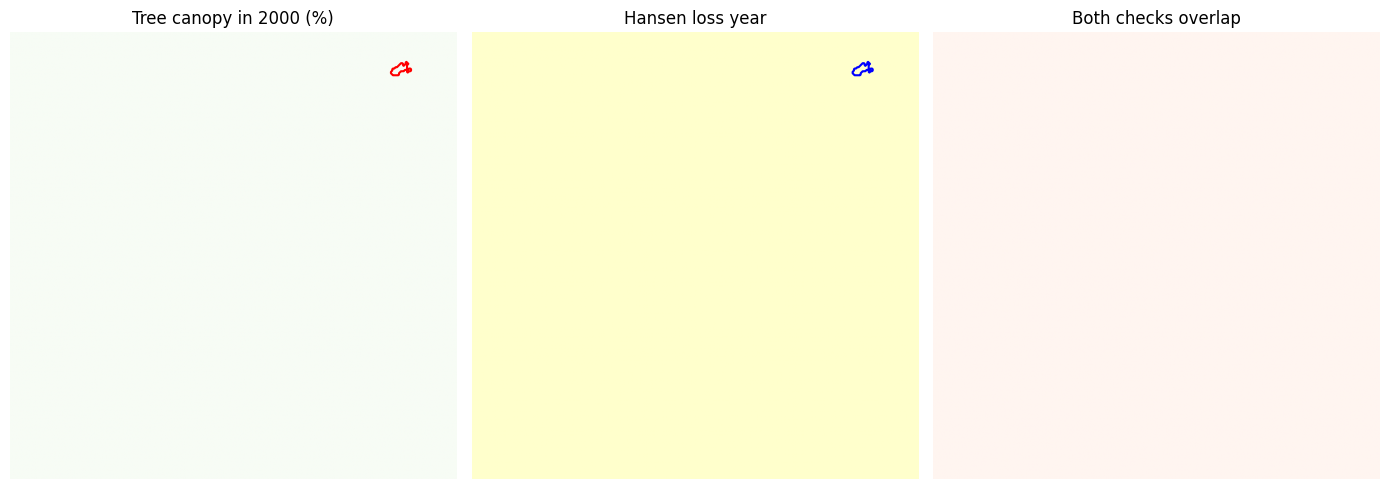

In [ ]:
#Check the largest candidate cluster

# Screening masks
historical_tree_cover = treecover2000 >= 30
recorded_loss_2021_2025 = (
    (lossyear >= 21) & (lossyear <= 25)
)

cluster_pixels = int(largest_cluster.sum())

treecover_overlap = largest_cluster & historical_tree_cover
loss_overlap = largest_cluster & recorded_loss_2021_2025
both_overlap = treecover_overlap & recorded_loss_2021_2025

print("Largest candidate cluster:", cluster_pixels, "pixels")
print(
    "Cluster pixels with >=30% canopy in 2000:",
    int(treecover_overlap.sum())
)
print(
    "Cluster pixels with recorded loss in 2021–2025:",
    int(loss_overlap.sum())
)
print(
    "Cluster pixels matching BOTH checks:",
    int(both_overlap.sum())
)
print(
    "Matching area (ha):",
    round(int(both_overlap.sum()) * 0.09, 2)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(treecover2000, cmap="Greens", vmin=0, vmax=100)
axes[0].contour(largest_cluster, levels=[0.5], colors="red")
axes[0].set_title("Tree canopy in 2000 (%)")

axes[1].imshow(lossyear, cmap="YlOrRd", vmin=0, vmax=25)
axes[1].contour(largest_cluster, levels=[0.5], colors="blue")
axes[1].set_title("Hansen loss year")

axes[2].imshow(both_overlap, cmap="Reds")
axes[2].set_title("Both checks overlap")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#erify the data alignment before rejecting the candidate

from rasterio.warp import transform
from pyproj import Transformer
import rasterio
import numpy as np

# Inspect the downloaded source files
for layer, path in downloaded_files.items():
    with rasterio.open(path) as src:
        data = src.read(1)
        print(f"\n{layer}")
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Shape:", data.shape)
        print("NoData:", src.nodata)
        print("Minimum / maximum:", data.min(), data.max())
        print("Nonzero pixels (%):", round(np.mean(data != 0) * 100, 3))

# Find the center of the largest HLS candidate cluster
rows, cols = np.where(largest_cluster)
center_row = int(np.round(rows.mean()))
center_col = int(np.round(cols.mean()))

x, y = rasterio.transform.xy(
    crop_transform, center_row, center_col
)

to_geo = Transformer.from_crs(
    crop_crs, "EPSG:4326", always_xy=True
)
lon, lat = to_geo.transform(x, y)

print("\nCandidate cluster center")
print("Longitude:", round(lon, 6))
print("Latitude:", round(lat, 6))

# Sample the original Hansen rasters at the candidate center
for layer, path in downloaded_files.items():
    with rasterio.open(path) as src:
        point_x, point_y = Transformer.from_crs(
            "EPSG:4326", src.crs, always_xy=True
        ).transform(lon, lat)

        sample_row, sample_col = src.index(point_x, point_y)

        if (0 <= sample_row < src.height
                and 0 <= sample_col < src.width):
            value = src.read(1)[sample_row, sample_col]
            print(f"{layer} at candidate center:", value)
        else:
            print(f"{layer}: candidate center is outside the raster")


treecover2000
CRS: EPSG:4326
Bounds: BoundingBox(left=70.0, bottom=0.0, right=80.0, top=10.0)
Shape: (40000, 40000)
NoData: None
Minimum / maximum: 0 100
Nonzero pixels (%): 1.593

lossyear
CRS: EPSG:4326
Bounds: BoundingBox(left=70.0, bottom=0.0, right=80.0, top=10.0)
Shape: (40000, 40000)
NoData: None
Minimum / maximum: 0 25
Nonzero pixels (%): 0.082

Candidate cluster center
Longitude: 76.984043
Latitude: 10.337516
treecover2000: candidate center is outside the raster
lossyear: candidate center is outside the raster


In [ ]:
#downloading the correct hansen dataset

import os
import requests

base_url = (
    "https://storage.googleapis.com/earthenginepartners-hansen/"
    "GFC-2025-v1.13/"
)

corrected_layers = {
    "treecover2000": (
        "Hansen_GFC-2025-v1.13_treecover2000_20N_070E.tif"
    ),
    "lossyear": (
        "Hansen_GFC-2025-v1.13_lossyear_20N_070E.tif"
    ),
}

corrected_files = {}

for layer, filename in corrected_layers.items():
    path = f"/content/{filename}"

    if not os.path.exists(path):
        response = requests.get(
            base_url + filename,
            stream=True,
            timeout=180
        )
        response.raise_for_status()

        with open(path, "wb") as f:
            for chunk in response.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)

    corrected_files[layer] = path

    print(f"\n{layer}")
    import rasterio
    with rasterio.open(path) as src:
        print("Bounds:", src.bounds)
        print("CRS:", src.crs)
        print("Shape:", src.shape)


treecover2000
Bounds: BoundingBox(left=70.0, bottom=10.0, right=80.0, top=20.0)
CRS: EPSG:4326
Shape: (40000, 40000)

lossyear
Bounds: BoundingBox(left=70.0, bottom=10.0, right=80.0, top=20.0)
CRS: EPSG:4326
Shape: (40000, 40000)


Candidate cluster: 70 pixels
Pixels with >=30% canopy in 2000: 68
Pixels with recorded loss in 2021–2025: 56
Pixels matching both checks: 54
Overlap area (ha): 4.86


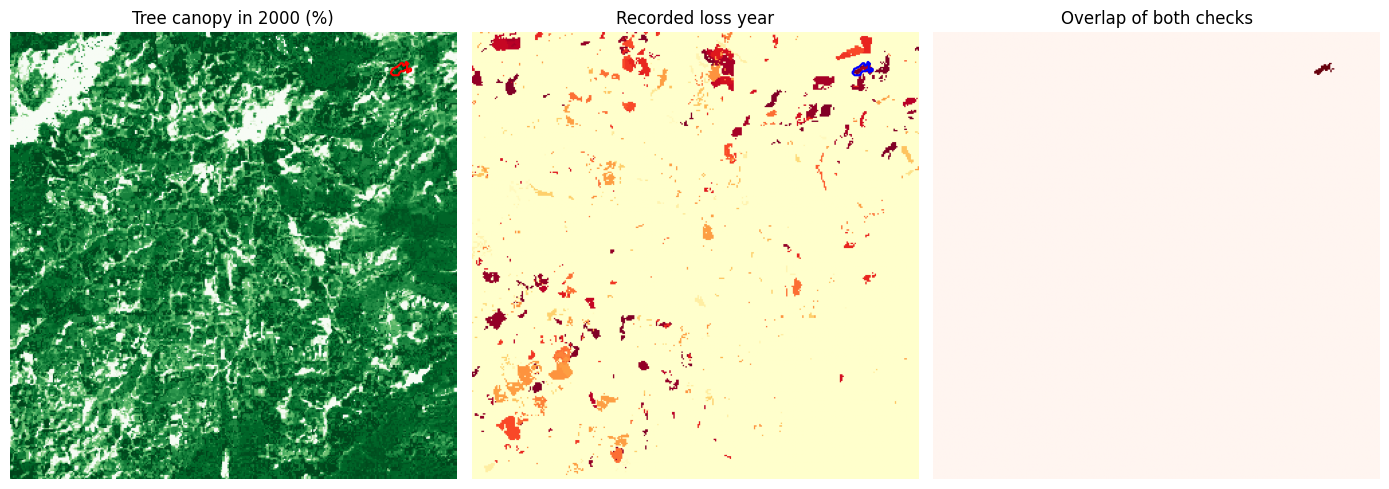

In [ ]:
#Reproject and validate the candidate

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.warp import reproject, Resampling

def read_hansen_on_hls_grid(path):
    output = np.zeros(
        (crop_height, crop_width), dtype=np.float32
    )

    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=output,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=crop_transform,
            dst_crs=crop_crs,
            dst_nodata=0,
            resampling=Resampling.nearest
        )

    return output

# Load the CORRECT tile
treecover2000_correct = read_hansen_on_hls_grid(
    corrected_files["treecover2000"]
)

lossyear_correct = read_hansen_on_hls_grid(
    corrected_files["lossyear"]
)

# Screen for historical tree canopy and recorded loss
historical_tree = treecover2000_correct >= 30
loss_2021_2025 = (
    (lossyear_correct >= 21)
    & (lossyear_correct <= 25)
)

tree_overlap = largest_cluster & historical_tree
loss_overlap = largest_cluster & loss_2021_2025
both_overlap = tree_overlap & loss_2021_2025

print("Candidate cluster:", int(largest_cluster.sum()), "pixels")
print(
    "Pixels with >=30% canopy in 2000:",
    int(tree_overlap.sum())
)
print(
    "Pixels with recorded loss in 2021–2025:",
    int(loss_overlap.sum())
)
print("Pixels matching both checks:", int(both_overlap.sum()))
print(
    "Overlap area (ha):",
    round(int(both_overlap.sum()) * 0.09, 2)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(
    treecover2000_correct, cmap="Greens", vmin=0, vmax=100
)
axes[0].contour(largest_cluster, levels=[0.5], colors="red")
axes[0].set_title("Tree canopy in 2000 (%)")

axes[1].imshow(
    lossyear_correct, cmap="YlOrRd", vmin=0, vmax=25
)
axes[1].contour(largest_cluster, levels=[0.5], colors="blue")
axes[1].set_title("Recorded loss year")

axes[2].imshow(both_overlap, cmap="Reds")
axes[2].set_title("Overlap of both checks")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Loss-year distribution inside the candidate cluster:
2021: 0 pixels (0.00 ha)
2022: 0 pixels (0.00 ha)
2023: 20 pixels (1.80 ha)
2024: 10 pixels (0.90 ha)
2025: 26 pixels (2.34 ha)


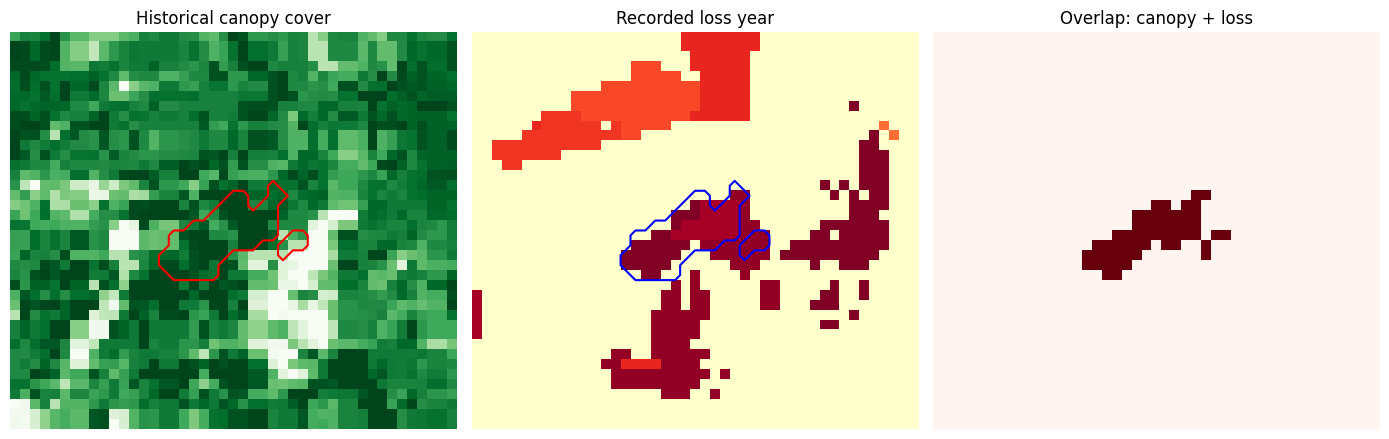

In [ ]:
#ind the recorded loss years

import numpy as np
import matplotlib.pyplot as plt

# Count recorded loss years within the candidate cluster
cluster_loss_years = lossyear_correct[largest_cluster].astype(int)

print("Loss-year distribution inside the candidate cluster:")
for code in range(21, 26):
    count = int(np.sum(cluster_loss_years == code))
    print(f"{2000 + code}: {count} pixels ({count * 0.09:.2f} ha)")

# Zoom around the candidate cluster
rows, cols = np.where(largest_cluster)

r0 = max(int(rows.min()) - 15, 0)
r1 = min(int(rows.max()) + 16, largest_cluster.shape[0])
c0 = max(int(cols.min()) - 15, 0)
c1 = min(int(cols.max()) + 16, largest_cluster.shape[1])

cluster_slice = np.s_[r0:r1, c0:c1]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(
    treecover2000_correct[cluster_slice],
    cmap="Greens", vmin=0, vmax=100
)
axes[0].contour(
    largest_cluster[cluster_slice],
    levels=[0.5], colors="red"
)
axes[0].set_title("Historical canopy cover")

axes[1].imshow(
    lossyear_correct[cluster_slice],
    cmap="YlOrRd", vmin=0, vmax=25
)
axes[1].contour(
    largest_cluster[cluster_slice],
    levels=[0.5], colors="blue"
)
axes[1].set_title("Recorded loss year")

axes[2].imshow(
    both_overlap[cluster_slice],
    cmap="Reds", vmin=0, vmax=1
)
axes[2].set_title("Overlap: canopy + loss")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#heck the reprojection and pixel alignment

import rasterio
import numpy as np

for layer, path in corrected_files.items():
    with rasterio.open(path) as src:
        print(f"\n{layer}")
        print("Source NoData:", src.nodata)
        print("Data type:", src.dtypes[0])
        print("Bounds:", src.bounds)
        print("Resolution:", src.res)
        print("Zero-value fraction:", round(
            float(np.mean(src.read(1) == 0)) * 100, 2
        ), "%")

print("\nHLS target grid")
print("CRS:", crop_crs)
print("Shape:", crop_height, crop_width)
print("Transform:", crop_transform)


treecover2000
Source NoData: None
Data type: uint8
Bounds: BoundingBox(left=70.0, bottom=10.0, right=80.0, top=20.0)
Resolution: (0.00025, 0.00025)
Zero-value fraction: 92.18 %

lossyear
Source NoData: None
Data type: uint8
Bounds: BoundingBox(left=70.0, bottom=10.0, right=80.0, top=20.0)
Resolution: (0.00025, 0.00025)
Zero-value fraction: 99.73 %

HLS target grid
CRS: PROJCS["UTM Zone 43, Northern Hemisphere",GEOGCS["Unknown datum based upon the WGS 84 ellipsoid",DATUM["Not specified (based on WGS 84 spheroid)",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Shape: 333 333
Transform: | 30.00, 0.00, 708540.

Tree-cover valid pixels: 110889
Loss-year valid pixels: 110889
Tree-cover range: 0.0 100.0
Loss-year range: 0.0 25.0

Candidate cluster pixels: 70
Historical canopy overlap: 68
Recorded loss overlap, 2021–2025: 56
Overlap of both checks: 54
Overlap area (ha): 4.86


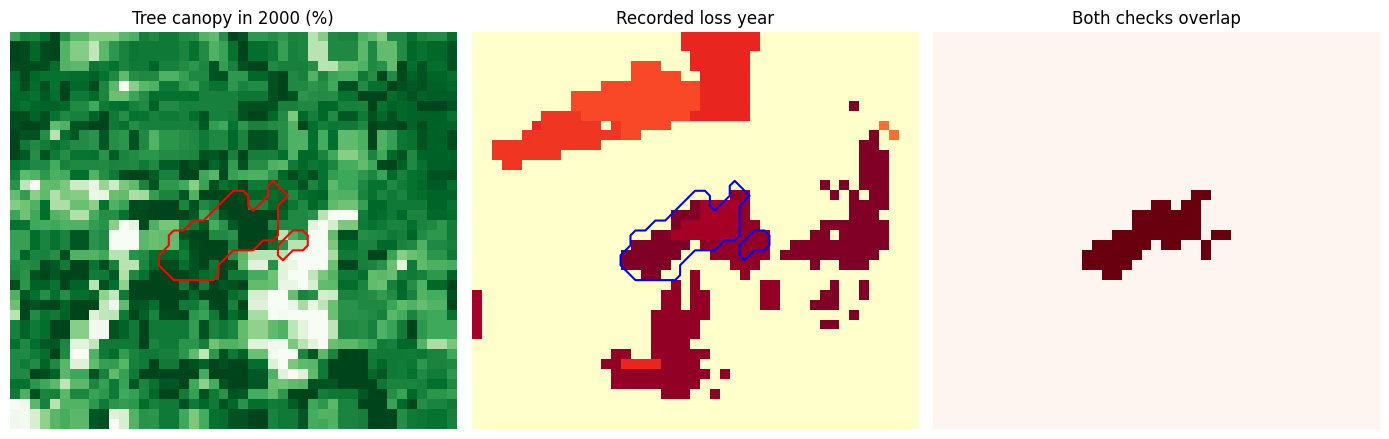

In [ ]:
#Correct the reprojection and recalculate validation

import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.warp import reproject, Resampling

DEST_NODATA = -9999.0

def read_hansen_on_hls_grid(path):
    output = np.full(
        (crop_height, crop_width),
        DEST_NODATA,
        dtype=np.float32
    )

    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=output,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,  # None: zero remains valid
            dst_transform=crop_transform,
            dst_crs=crop_crs,
            dst_nodata=DEST_NODATA,
            resampling=Resampling.nearest,
            init_dest_nodata=True
        )

    return output

# Reproject the corrected Hansen tiles
treecover_fixed = read_hansen_on_hls_grid(
    corrected_files["treecover2000"]
)
lossyear_fixed = read_hansen_on_hls_grid(
    corrected_files["lossyear"]
)

# Identify actual output pixels versus destination NoData
tree_valid = treecover_fixed != DEST_NODATA
loss_valid = lossyear_fixed != DEST_NODATA

print("Tree-cover valid pixels:", int(tree_valid.sum()))
print("Loss-year valid pixels:", int(loss_valid.sum()))
print("Tree-cover range:", treecover_fixed[tree_valid].min(),
      treecover_fixed[tree_valid].max())
print("Loss-year range:", lossyear_fixed[loss_valid].min(),
      lossyear_fixed[loss_valid].max())

# Recalculate the candidate overlap
historical_tree = tree_valid & (treecover_fixed >= 30)
recorded_loss = (
    loss_valid
    & (lossyear_fixed >= 21)
    & (lossyear_fixed <= 25)
)

tree_overlap = largest_cluster & historical_tree
loss_overlap = largest_cluster & recorded_loss
both_overlap = tree_overlap & loss_overlap

print("\nCandidate cluster pixels:", int(largest_cluster.sum()))
print("Historical canopy overlap:", int(tree_overlap.sum()))
print("Recorded loss overlap, 2021–2025:", int(loss_overlap.sum()))
print("Overlap of both checks:", int(both_overlap.sum()))
print("Overlap area (ha):", round(int(both_overlap.sum()) * 0.09, 2))

# Plot only the candidate neighborhood
rows, cols = np.where(largest_cluster)
r0, r1 = max(rows.min()-15, 0), min(rows.max()+16, crop_height)
c0, c1 = max(cols.min()-15, 0), min(cols.max()+16, crop_width)
s = np.s_[r0:r1, c0:c1]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(
    np.ma.masked_where(~tree_valid[s], treecover_fixed[s]),
    cmap="Greens", vmin=0, vmax=100
)
axes[0].contour(largest_cluster[s], levels=[0.5], colors="red")
axes[0].set_title("Tree canopy in 2000 (%)")

axes[1].imshow(
    np.ma.masked_where(~loss_valid[s], lossyear_fixed[s]),
    cmap="YlOrRd", vmin=0, vmax=25
)
axes[1].contour(largest_cluster[s], levels=[0.5], colors="blue")
axes[1].set_title("Recorded loss year")

axes[2].imshow(both_overlap[s], cmap="Reds", vmin=0, vmax=1)
axes[2].set_title("Both checks overlap")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#calculate the final loss-year breakdown

print("Corrected Hansen loss-year breakdown")
print("------------------------------------")

for year in range(2021, 2026):
    code = year - 2000

    year_mask = (
        largest_cluster
        & loss_valid
        & (lossyear_fixed == code)
    )

    pixels = int(year_mask.sum())
    print(
        f"{year}: {pixels} pixels, "
        f"{pixels * 0.09:.2f} hectares"
    )

print("\nPixels with historical canopy and recorded loss")
print("------------------------------------------------")

for year in range(2021, 2026):
    code = year - 2000

    year_mask = (
        largest_cluster
        & tree_valid
        & (treecover_fixed >= 30)
        & loss_valid
        & (lossyear_fixed == code)
    )

    print(
        f"{year}: {int(year_mask.sum())} pixels, "
        f"{int(year_mask.sum()) * 0.09:.2f} hectares"
    )

Corrected Hansen loss-year breakdown
------------------------------------
2021: 0 pixels, 0.00 hectares
2022: 0 pixels, 0.00 hectares
2023: 20 pixels, 1.80 hectares
2024: 10 pixels, 0.90 hectares
2025: 26 pixels, 2.34 hectares

Pixels with historical canopy and recorded loss
------------------------------------------------
2021: 0 pixels, 0.00 hectares
2022: 0 pixels, 0.00 hectares
2023: 20 pixels, 1.80 hectares
2024: 8 pixels, 0.72 hectares
2025: 26 pixels, 2.34 hectares


FINAL STUDY SUMMARY
Study grid: 333 x 333
Pixel size: 30 m x 30 m
Common valid coverage (%): 14.11
NDVI decline candidates: 212
Hansen-supported pixels: 2283
Overlapping candidate pixels: 93
Overlapping candidate area (ha): 8.37
2021 overlap: 0 pixels, 0.00 ha
2022 overlap: 0 pixels, 0.00 ha
2023 overlap: 20 pixels, 1.80 ha
2024 overlap: 34 pixels, 3.06 ha
2025 overlap: 39 pixels, 3.51 ha


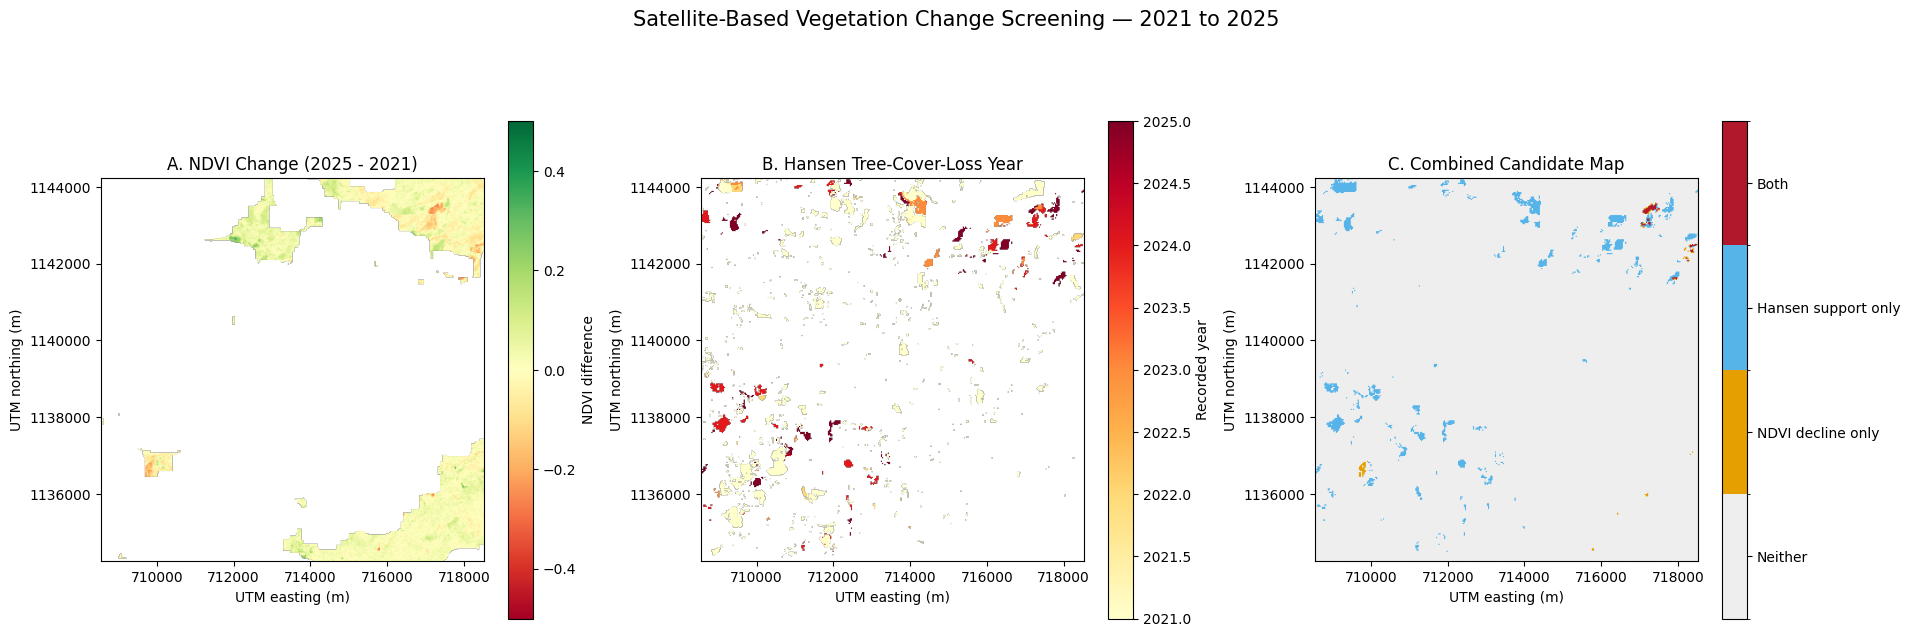


Saved map: /content/forest_loss_results/final_forest_loss_candidate_map.png

Exported files:
/content/forest_loss_results/combined_candidate_classes.tif
/content/forest_loss_results/final_forest_loss_candidate_map.png
/content/forest_loss_results/hansen_loss_year.tif
/content/forest_loss_results/ndvi_change_2021_2025.tif


In [ ]:
#Generate the final map and export the files

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.transform import array_bounds

# --------------------------------------------------
# 1. Prepare aligned data and candidate categories
# --------------------------------------------------

output_dir = "/content/forest_loss_results"
os.makedirs(output_dir, exist_ok=True)

# Independent Hansen screening evidence:
# historical canopy >= 30% and loss recorded in 2021-2025
historical_tree = (
    tree_valid
    & (treecover_fixed >= 30)
)

recorded_loss = (
    loss_valid
    & (lossyear_fixed >= 21)
    & (lossyear_fixed <= 25)
)

hansen_support = historical_tree & recorded_loss

# NDVI decline candidates are already restricted to pixels
# with valid observations in both years.
ndvi_candidates = decline_mask.copy()

# Categories:
# 0 = neither screening condition
# 1 = NDVI decline only
# 2 = Hansen support only
# 3 = NDVI decline + Hansen support
combined = np.zeros(
    ndvi_candidates.shape, dtype=np.uint8
)

combined[ndvi_candidates & ~hansen_support] = 1
combined[~ndvi_candidates & hansen_support] = 2
combined[ndvi_candidates & hansen_support] = 3

combined_candidates = (
    ndvi_candidates & hansen_support
)

pixel_area_ha = 0.09

print("FINAL STUDY SUMMARY")
print("=" * 40)
print("Study grid:", crop_height, "x", crop_width)
print("Pixel size: 30 m x 30 m")
print("Common valid coverage (%):",
      round(common_valid.mean() * 100, 2))
print("NDVI decline candidates:",
      int(ndvi_candidates.sum()))
print("Hansen-supported pixels:",
      int(hansen_support.sum()))
print("Overlapping candidate pixels:",
      int(combined_candidates.sum()))
print("Overlapping candidate area (ha):",
      round(combined_candidates.sum() * pixel_area_ha, 2))

# Loss-year summary within overlapping candidates
for year in range(2021, 2026):
    count = int(np.sum(
        combined_candidates
        & (lossyear_fixed == year - 2000)
    ))
    print(
        f"{year} overlap: {count} pixels, "
        f"{count * pixel_area_ha:.2f} ha"
    )

# --------------------------------------------------
# 2. Create the three-panel final map
# --------------------------------------------------

west, south, east, north = array_bounds(
    crop_height, crop_width, crop_transform
)
extent = [west, east, south, north]

fig, axes = plt.subplots(
    1, 3, figsize=(19, 7), constrained_layout=True
)

# Panel A: NDVI change
ndvi_plot = np.ma.masked_invalid(ndvi_change)

im0 = axes[0].imshow(
    ndvi_plot,
    cmap="RdYlGn",
    vmin=-0.5,
    vmax=0.5,
    extent=extent,
    origin="upper"
)
axes[0].set_title("A. NDVI Change (2025 - 2021)")
fig.colorbar(im0, ax=axes[0], shrink=0.75,
             label="NDVI difference")

# Panel B: Hansen-recorded loss year
loss_year_display = lossyear_fixed.copy()
loss_year_display[~loss_valid] = np.nan
loss_year_display[loss_year_display == 0] = np.nan
loss_year_display[loss_year_display > 0] += 2000

im1 = axes[1].imshow(
    loss_year_display,
    cmap="YlOrRd",
    vmin=2021,
    vmax=2025,
    extent=extent,
    origin="upper"
)
axes[1].set_title("B. Hansen Tree-Cover-Loss Year")
fig.colorbar(im1, ax=axes[1], shrink=0.75,
             label="Recorded year")

# Panel C: Combined screening categories
cmap = ListedColormap([
    "#eeeeee",  # neither
    "#e69f00",  # NDVI decline only
    "#56b4e9",  # Hansen support only
    "#b2182b"   # both
])
norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N
)

im2 = axes[2].imshow(
    combined,
    cmap=cmap,
    norm=norm,
    extent=extent,
    origin="upper"
)
axes[2].set_title("C. Combined Candidate Map")

cbar = fig.colorbar(
    im2, ax=axes[2], shrink=0.75,
    ticks=[0, 1, 2, 3]
)
cbar.ax.set_yticklabels([
    "Neither",
    "NDVI decline only",
    "Hansen support only",
    "Both"
])

for ax in axes:
    ax.set_xlabel("UTM easting (m)")
    ax.set_ylabel("UTM northing (m)")
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.set_aspect("equal")

fig.suptitle(
    "Satellite-Based Vegetation Change Screening — 2021 to 2025",
    fontsize=15
)

map_path = os.path.join(
    output_dir, "final_forest_loss_candidate_map.png"
)
fig.savefig(map_path, dpi=250, bbox_inches="tight")
plt.show()

print("\nSaved map:", map_path)

# --------------------------------------------------
# 3. Export georeferenced GeoTIFFs
# --------------------------------------------------

with rasterio.open(files[2021]["B04"]) as src:
    profile = src.profile.copy()

profile.update(
    driver="GTiff",
    height=crop_height,
    width=crop_width,
    transform=crop_transform,
    crs=crop_crs,
    compress="deflate"
)

# NDVI change raster
ndvi_export = np.where(
    np.isfinite(ndvi_change),
    ndvi_change,
    -9999
).astype(np.float32)

ndvi_profile = profile.copy()
ndvi_profile.update(dtype="float32", nodata=-9999)

with rasterio.open(
    os.path.join(output_dir, "ndvi_change_2021_2025.tif"),
    "w", **ndvi_profile
) as dst:
    dst.write(ndvi_export, 1)
    dst.set_band_description(
        1, "NDVI difference: 2025 minus 2021"
    )

# Combined candidate category raster
combined_profile = profile.copy()
combined_profile.update(dtype="uint8", nodata=255)

with rasterio.open(
    os.path.join(output_dir, "combined_candidate_classes.tif"),
    "w", **combined_profile
) as dst:
    dst.write(combined, 1)
    dst.set_band_description(
        1,
        "0 neither; 1 NDVI decline; "
        "2 Hansen support; 3 both"
    )

# Hansen loss-year raster
loss_export = np.where(
    loss_valid, lossyear_fixed, 255
).astype(np.uint8)

loss_profile = profile.copy()
loss_profile.update(dtype="uint8", nodata=255)

with rasterio.open(
    os.path.join(output_dir, "hansen_loss_year.tif"),
    "w", **loss_profile
) as dst:
    dst.write(loss_export, 1)
    dst.set_band_description(
        1, "Hansen loss-year code: 21=2021 ... 25=2025; 0=no recorded loss"
    )

print("\nExported files:")
for filename in sorted(os.listdir(output_dir)):
    print(os.path.join(output_dir, filename))

In [ ]:
#downloading results

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/forest_loss_results",
    "zip",
    output_dir
)

print("Created:", zip_path)
files.download(zip_path)

Created: /content/forest_loss_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>